# ICSS — Explainable Intelligent Clinical Support System
### Multimodal CT–MRI brain tumor segmentation & classification
**AGAU-Net** (attention-guided adaptive U-Net) → **HFSN** (MIG + entropy hybrid feature selection) → **TA-GCN** (transformer-augmented graph convolutional network) → **XAI** (Grad-CAM · SHAP · LIME) → clinician report.

This notebook implements the full pipeline end to end:

| § | Stage | What it does |
|---|---|---|
| 1 | Setup & configuration | Installs, imports, every hyper-parameter in one `CFG` dict |
| 2 | Data | Downloads the Figshare brain-tumor dataset (3,064 T1-CE slices, 233 patients) and reads the MATLAB v7.3 files; optional paired-CT folder and optional non-tumor folder |
| 3 | Pre-processing | Resampling to 256², N4 bias correction, skull stripping, z-score (MRI); HU windowing WC 40 / WW 80 + min–max (CT); non-local-means denoising; cached to disk |
| 4 | Split & augmentation | Patient-level 70 : 15 : 15 split, rotation ±15°, flip, elastic, contrast jitter |
| 5 | AGAU-Net | Residual encoder–decoder with adaptive channel-wise attention gates `x̂ = λ·(x ⊙ α)`, loss `0.7·Dice + 0.3·wBCE`, baselines U-Net / Attention U-Net / V-Net |
| 6 | Feature bank | ROI from the predicted mask → G×G sub-regions → 128 radiomic + 896 deep (encoder RoI-Align) = **1,024-d per node** |
| 7 | HFSN | `Score(f) = α·MIGₙ(f) + (1−α)·Hₙ(f)`, α = 0.6, top-k = 256 |
| 8 | TA-GCN | Region-adjacency graph (spatial ∪ cos-sim > τ ∪ CT↔MRI), 2 × GCN, multi-head self-attention, attention pooling, class-weighted CE; baselines CNN / GCN / Transformer |
| 9 | Main run | Trains and evaluates the full ICSS |
| 10 | Comparisons | Segmentation & classification baselines, ablation, grid search of α, k, τ, 5-fold CV + Wilcoxon |
| 11 | XAI | Grad-CAM on the AGAU-Net decoder, SHAP on the HFSN features, LIME on graph nodes, unified report & dashboard |
| 12 | Efficiency & export | Inference timing, saving all models and results |

**Runtime:** use a GPU runtime (*Runtime → Change runtime type → T4 GPU*). The main run (§9) takes roughly 1–2 h on a T4 with the paper's settings (150 epochs, early stopping). Set `QUICK=True` in §1 for a ~10-minute smoke test. The optional sections in §10 retrain the pipeline several times; they are off by default.

**Data notes.** The public Figshare set contains MRI only and only tumor slices. The paired CT subset described in the paper is institutional; if you have it, point `PAIRED_CT_DIR` at a folder of co-registered CT slices named `<figshare_id>.npy` (HU) or `.png` (already windowed) and the pipeline switches to two-channel CT+MRI input with cross-modal graph edges. For the 4th *non-tumor* class, point `NONTUMOR_DIR` at a folder of normal T1 slices (e.g. the *notumor* folder of the Kaggle *Brain Tumor MRI Dataset*). Without it the classifier runs on the 3 tumor classes.

## 1 · Setup & configuration

In [ ]:
# Colab already ships torch, torchvision, opencv, scikit-image, scikit-learn, h5py, pandas, matplotlib
!pip -q install SimpleITK shap lime

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import os, re, glob, json, math, time, random, zipfile, shutil, subprocess, warnings, copy, hashlib
import numpy as np, pandas as pd
import h5py, cv2
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.stats import wilcoxon, skew, kurtosis
from skimage.filters import threshold_otsu
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from skimage.measure import regionprops, perimeter
from skimage.morphology import disk
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, roc_auc_score,
                             confusion_matrix, mutual_info_score, roc_curve)
from joblib import Parallel, delayed
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset
from torchvision.ops import roi_align
warnings.filterwarnings('ignore')
try:
    import SimpleITK as sitk
except ImportError:
    sitk = None

CFG = dict(
    # ---- paths ----
    DATA_DIR='/content/figshare_brain_tumor',   # .mat files are searched recursively here
    WORK_DIR='/content/icss_work',              # cache, checkpoints, figures, results
    DOWNLOAD=True,                              # download Figshare 1512427 v5 if no .mat files found
    PAIRED_CT_DIR=None,                         # folder of co-registered CT: <id>.npy (HU) or <id>.png
    NONTUMOR_DIR=None,                          # folder of normal MRI slices -> 4th class "Non-tumor"
    # ---- pre-processing ----
    IMG_SIZE=256, USE_N4=True, N4_SHRINK=4, N4_ITERS=[20, 20, 10],
    SKULL_STRIP=True, SKULL_ERODE_FRAC=0.02, NLM_H=6,
    CT_WC=40, CT_WW=80, PIXEL_MM=0.49 * 512 / 256,  # in-plane spacing after resampling (Figshare ≈0.49 mm @512)
    # ---- split / training ----
    SPLIT=(0.70, 0.15, 0.15), SEED=42, N_FOLDS=5,
    BATCH=16, LR=1e-4, WEIGHT_DECAY=1e-4, EPOCHS_SEG=150, EPOCHS_CLS=150, PATIENCE=15, NUM_WORKERS=2,
    # ---- AGAU-Net ----
    BASE_CH=32, LAMBDA_DICE=0.7, LAMBDA_BCE=0.3, MASK_THR=0.5,
    # ---- feature bank / HFSN ----
    GRID=4,                 # ROI split into GRID x GRID sub-regions = graph nodes per modality
    ROI_MARGIN=0.15, ROI_MIN=32,
    TOPK=256, ALPHA=0.6, ENTROPY_BINS=32, FEAT_AUG_COPIES=1,   # extra augmented copies of training slices
    # ---- TA-GCN ----
    TAU=0.8, GCN_HIDDEN=128, N_HEADS=4, DROPOUT=0.3,
    # ---- XAI ----
    SHAP_BACKGROUND=64, SHAP_SAMPLES=100, LIME_SAMPLES=1000,
    # ---- what to run ----
    QUICK=False,            # smoke test: few epochs
    RUN_BASELINES=True,     # U-Net / Attention U-Net / V-Net and CNN / GCN / Transformer (≈ +1.5 h on T4)
    RUN_ABLATION=False,     # w/o adaptive AG (retrains segmentation), w/o HFSN, w/o transformer
    RUN_GRID_SEARCH=False,  # α, k, τ on the validation split
    RUN_CV=False,           # 5-fold patient-level CV of the full pipeline + Wilcoxon tests (≈ 5 × main run)
    N_JOBS=-1,
)
_ov = os.environ.get('ICSS_CFG')          # optional JSON override (handy for scripted runs)
if _ov: CFG.update(json.loads(_ov))
if CFG['QUICK']:
    CFG.update(EPOCHS_SEG=min(CFG['EPOCHS_SEG'], 4), EPOCHS_CLS=min(CFG['EPOCHS_CLS'], 15), PATIENCE=5,
               LIME_SAMPLES=min(CFG['LIME_SAMPLES'], 300), SHAP_SAMPLES=min(CFG['SHAP_SAMPLES'], 20))
os.makedirs(CFG['WORK_DIR'], exist_ok=True)
FIG_DIR = os.path.join(CFG['WORK_DIR'], 'figures'); os.makedirs(FIG_DIR, exist_ok=True)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP = DEVICE.type == 'cuda'
def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(CFG['SEED'])

CLASS_NAMES_ALL = ['Glioma', 'Meningioma', 'Pituitary', 'Non-tumor']
FIG_LABEL_MAP = {2: 0, 1: 1, 3: 2}    # Figshare: 1 = meningioma, 2 = glioma, 3 = pituitary
print('device:', DEVICE, '| torch', torch.__version__, '| SimpleITK', 'ok' if sitk else 'missing (N4 skipped)')

device: cuda | torch 2.11.0+cu130 | SimpleITK ok


## 2 · Data — Figshare brain tumor dataset (+ optional CT / non-tumor)

In [ ]:
FIGSHARE_URL = 'https://ndownloader.figshare.com/articles/1512427/versions/5'

def download_figshare(dst):
    os.makedirs(dst, exist_ok=True)
    if len(glob.glob(os.path.join(dst, '**', '*.mat'), recursive=True)) > 100:
        print('Figshare .mat files already present'); return
    zp = os.path.join(dst, 'figshare_1512427_v5.zip')
    if not os.path.exists(zp):
        print('Downloading Figshare brain tumor dataset (~880 MB)…')
        subprocess.run(['wget', '-q', '--show-progress', '-O', zp, FIGSHARE_URL], check=True)
    with zipfile.ZipFile(zp) as z: z.extractall(dst)
    inner = sorted(glob.glob(os.path.join(dst, 'brainTumorDataPublic_*.zip')))
    out = os.path.join(dst, 'mat'); os.makedirs(out, exist_ok=True)
    try:
        for f in inner:
            with zipfile.ZipFile(f) as z: z.extractall(out)
    except zipfile.BadZipFile:   # parts of one split archive -> concatenate and repair
        cat = os.path.join(dst, 'all_parts.zip')
        with open(cat, 'wb') as w:
            for f in inner: w.write(open(f, 'rb').read())
        subprocess.run(['zip', '-q', '-FF', cat, '--out', os.path.join(dst, 'fixed.zip')], input=b'y\n', check=False)
        with zipfile.ZipFile(os.path.join(dst, 'fixed.zip')) as z: z.extractall(out)
    for f in inner: os.remove(f)
    print('extracted', len(glob.glob(os.path.join(out, '*.mat'))), '.mat files')

def load_mat(fp):
    # MATLAB v7.3 (HDF5) struct `cjdata`; arrays come out transposed through h5py
    with h5py.File(fp, 'r') as f:
        cj = f['cjdata']
        img = np.array(cj['image']).T.astype(np.float32)
        mask = np.array(cj['tumorMask']).T.astype(np.uint8)
        label = int(np.array(cj['label']).squeeze())
        pid = ''.join(chr(int(c)) for c in np.array(cj['PID']).flatten() if int(c) > 0)
    return img, mask, label, pid

def load_ct(path):
    # returns (array, is_hu)
    if path.endswith('.npy'): return np.load(path).astype(np.float32), True
    return cv2.imread(path, cv2.IMREAD_GRAYSCALE).astype(np.float32), False

def list_sources():
    num = lambda p: int(re.sub(r'\D', '', os.path.basename(p)) or 0)
    mats = sorted(glob.glob(os.path.join(CFG['DATA_DIR'], '**', '*.mat'), recursive=True), key=num)
    mats = [m for m in mats if 'cvind' not in os.path.basename(m).lower()]
    src = []
    for m in mats:
        sid = os.path.splitext(os.path.basename(m))[0]
        ct = None
        if CFG['PAIRED_CT_DIR']:
            for ext in ('.npy', '.png'):
                p = os.path.join(CFG['PAIRED_CT_DIR'], sid + ext)
                if os.path.exists(p): ct = p; break
        src.append(dict(kind='mat', path=m, id=sid, ct=ct))
    if CFG['NONTUMOR_DIR']:
        nts = sorted(sum([glob.glob(os.path.join(CFG['NONTUMOR_DIR'], '**', e), recursive=True)
                          for e in ('*.png', '*.jpg', '*.jpeg', '*.tif')], []))
        for p in nts:
            sid = 'NT_' + os.path.splitext(os.path.basename(p))[0]
            src.append(dict(kind='nontumor', path=p, id=sid, ct=None, pid=sid))  # one pseudo-patient per slice
    return src

## 3 · Pre-processing
MRI: resample → N4 bias-field correction → skull stripping → non-local-means denoising → z-score within the brain (mapped to [0, 1], background 0).
CT: resample → HU brain window (WC ≈ 40, WW ≈ 80) → non-local-means → min–max.
Results are cached, so this runs once.

In [ ]:
def norm01(x, lo=0.5, hi=99.5, m=None):
    v = x[m] if m is not None and m.any() else x
    a, b = np.percentile(v, lo), np.percentile(v, hi)
    return np.clip((x - a) / (b - a + 1e-8), 0, 1)

def largest_cc(m):
    lab, n = ndi.label(m)
    if n == 0: return m
    sizes = ndi.sum(m, lab, range(1, n + 1))
    return lab == (np.argmax(sizes) + 1)

def n4_correct(img):
    if sitk is None: return img
    im = sitk.GetImageFromArray((img - img.min() + 1.0).astype(np.float32))
    msk = sitk.OtsuThreshold(im, 0, 1, 200)
    s = CFG['N4_SHRINK']
    corr = sitk.N4BiasFieldCorrectionImageFilter()
    corr.SetMaximumNumberOfIterations(list(CFG['N4_ITERS']))
    corr.Execute(sitk.Shrink(im, [s, s]), sitk.Shrink(msk, [s, s]))
    log_bias = corr.GetLogBiasFieldAsImage(im)
    return sitk.GetArrayFromImage(im / sitk.Exp(log_bias)).astype(np.float32)

def brain_mask(img):
    # heuristic skull stripping for 2-D T1-CE slices: head mask -> erosion -> largest component -> fill
    x = norm01(img)
    head = ndi.binary_fill_holes(largest_cc(x > 0.5 * threshold_otsu(x)))
    if not CFG['SKULL_STRIP']: return head
    r = max(1, int(round(CFG['IMG_SIZE'] * CFG['SKULL_ERODE_FRAC'])))
    b = ndi.binary_erosion(head, structure=disk(r))
    b = ndi.binary_fill_holes(largest_cc(b)) if b.any() else head
    return ndi.binary_dilation(b, structure=disk(max(1, r // 2)))

def nlm(x01):
    u8 = (np.clip(x01, 0, 1) * 255).astype(np.uint8)
    return cv2.fastNlMeansDenoising(u8, None, h=CFG['NLM_H'], templateWindowSize=5, searchWindowSize=13).astype(np.float32) / 255.

def preprocess_mri(img):
    S = CFG['IMG_SIZE']
    img = cv2.resize(img.astype(np.float32), (S, S), interpolation=cv2.INTER_AREA)
    if CFG['USE_N4']: img = n4_correct(img)
    b = brain_mask(img)
    x = nlm(norm01(img, m=b))
    mu, sd = x[b].mean(), x[b].std() + 1e-6
    z = (np.clip((x - mu) / sd, -3, 5) + 3) / 8.0
    z[~b] = 0
    return z.astype(np.float32), b

def preprocess_ct(ct, is_hu):
    S = CFG['IMG_SIZE']
    ct = cv2.resize(ct, (S, S), interpolation=cv2.INTER_AREA)
    x = np.clip((ct - (CFG['CT_WC'] - CFG['CT_WW'] / 2)) / CFG['CT_WW'], 0, 1) if is_hu else ct / 255.
    x = nlm(x)
    return ((x - x.min()) / (np.ptp(x) + 1e-8)).astype(np.float32)

def process_source(j):
    try:
        if j['kind'] == 'mat':
            img, mask, lab, pid = load_mat(j['path']); lab = FIG_LABEL_MAP[lab]
        else:
            img = cv2.imread(j['path'], cv2.IMREAD_GRAYSCALE).astype(np.float32)
            mask = np.zeros_like(img, np.uint8); lab = 3; pid = j['pid']
    except Exception as e:
        return None
    S = CFG['IMG_SIZE']
    mri, b = preprocess_mri(img)
    chans = [mri]
    if j['ct']:
        ct, is_hu = load_ct(j['ct']); chans.append(preprocess_ct(ct, is_hu))
    mask = cv2.resize(mask, (S, S), interpolation=cv2.INTER_NEAREST)
    return dict(id=j['id'], img=np.stack(chans).astype(np.float16), mask=mask.astype(np.uint8),
                brain=b.astype(np.uint8), label=lab, pid=pid, has_ct=j['ct'] is not None)

def prepare_data():
    keys = ['IMG_SIZE', 'USE_N4', 'N4_SHRINK', 'SKULL_STRIP', 'SKULL_ERODE_FRAC', 'NLM_H', 'CT_WC', 'CT_WW',
            'PAIRED_CT_DIR', 'NONTUMOR_DIR', 'DATA_DIR']
    h = hashlib.md5(json.dumps({k: CFG[k] for k in keys}, sort_keys=True, default=str).encode()).hexdigest()[:8]
    cache = os.path.join(CFG['WORK_DIR'], f'preprocessed_{h}.npz')
    if os.path.exists(cache):
        z = np.load(cache, allow_pickle=True); print('loaded cache', cache)
        return {k: z[k] for k in z.files}
    if CFG['DOWNLOAD']: download_figshare(CFG['DATA_DIR'])
    src = list_sources()
    if CFG['PAIRED_CT_DIR']:
        src = [s for s in src if s['ct'] is not None]
        print(f'paired CT found for {len(src)} slices -> multimodal CT+MRI mode')
    assert len(src) > 0, 'no input data found'
    t = time.time()
    out = Parallel(n_jobs=CFG['N_JOBS'], verbose=0)(delayed(process_source)(s) for s in src)
    out = [o for o in out if o is not None]
    D = dict(img=np.stack([o['img'] for o in out]), mask=np.stack([o['mask'] for o in out]),
             brain=np.stack([o['brain'] for o in out]), label=np.array([o['label'] for o in out]),
             pid=np.array([o['pid'] for o in out]), id=np.array([o['id'] for o in out]))
    np.savez_compressed(cache, **D)
    print(f'pre-processed {len(out)} slices in {time.time() - t:.0f}s -> {cache}')
    return D

data = prepare_data()
N_CH = data['img'].shape[1]
CLASS_NAMES = CLASS_NAMES_ALL[:int(data['label'].max()) + 1]
N_CLASSES = len(CLASS_NAMES)
MODALITIES = ['MRI', 'CT'][:N_CH]
summary = pd.DataFrame({'class': [CLASS_NAMES[l] for l in data['label']], 'pid': data['pid']})
print(summary.groupby('class').agg(slices=('pid', 'size'), patients=('pid', 'nunique')))
print('total slices', len(summary), '| patients', summary.pid.nunique(), '| input channels', N_CH, MODALITIES)

extracted 3064 .mat files
pre-processed 3064 slices in 432s -> /content/icss_work/preprocessed_66d4545a.npz
            slices  patients
class                       
Glioma        1426        89
Meningioma     708        82
Pituitary      930        62
total slices 3064 | patients 233 | input channels 1 ['MRI']


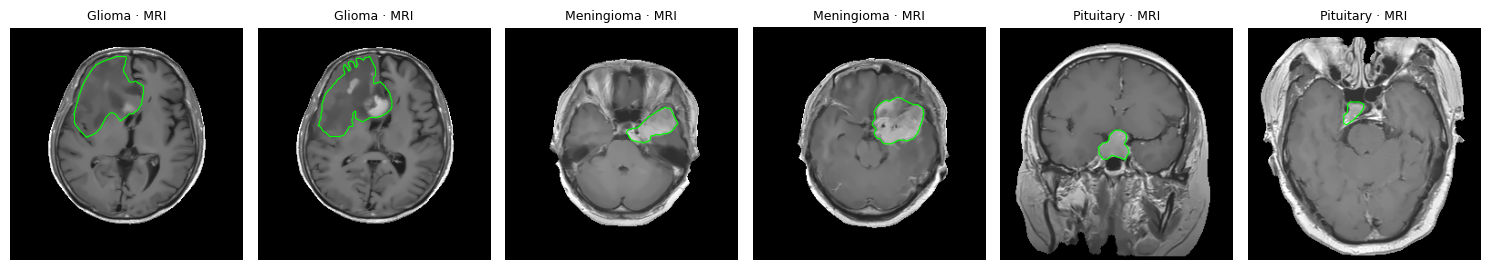

In [ ]:
# quick look at the pre-processed data
fig, ax = plt.subplots(N_CH, 6, figsize=(15, 2.7 * N_CH), squeeze=False)
for k, c in enumerate(range(min(N_CLASSES, 3))):
    for j, i in enumerate(np.where(data['label'] == c)[0][:2]):
        for m in range(N_CH):
            a = ax[m, k * 2 + j]; a.imshow(data['img'][i, m].astype(np.float32), cmap='gray')
            if data['mask'][i].any(): a.contour(data['mask'][i], [0.5], colors='lime', linewidths=0.8)
            a.set_title(f'{CLASS_NAMES[c]} · {MODALITIES[m]}', fontsize=9); a.axis('off')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/data_examples.png', dpi=150); plt.show()

## 4 · Patient-level split & augmentation

In [ ]:
def patient_split(pids, labels, fr=CFG['SPLIT'], seed=CFG['SEED']):
    # stratified by each patient's (majority) label, so no patient appears in two partitions
    rng = np.random.default_rng(seed)
    dfp = pd.DataFrame({'pid': pids, 'y': labels}).groupby('pid').y.agg(lambda s: s.mode()[0])
    tr, va, te = [], [], []
    for y in sorted(dfp.unique()):
        p = dfp[dfp == y].index.values.copy(); rng.shuffle(p)
        n = len(p); a = int(round(fr[0] * n)); b = int(round((fr[0] + fr[1]) * n))
        if n >= 3 and fr[2] > 0: a = min(max(a, 1), n - 2); b = min(max(b, a + 1), n - 1)
        elif n >= 2 and fr[1] > 0: a = min(max(a, 1), n - 1); b = n
        tr += list(p[:a]); va += list(p[a:b]); te += list(p[b:])
    idx = lambda P: np.where(np.isin(pids, P))[0]
    return idx(tr), idx(va), idx(te)

tr_idx, va_idx, te_idx = patient_split(data['pid'], data['label'])
for n_, ix in [('train', tr_idx), ('val', va_idx), ('test', te_idx)]:
    print(f'{n_:5s}: {len(ix):5d} slices, {len(np.unique(data["pid"][ix])):4d} patients,',
          np.bincount(data['label'][ix], minlength=N_CLASSES))
assert not set(data['pid'][tr_idx]) & set(data['pid'][te_idx])

def augment(img, mask, rng):
    # img [C,H,W] float32, mask [H,W]; rotation ±15°, horizontal flip, elastic deformation, contrast jitter
    C, H, W = img.shape
    img = img.copy(); mask = mask.copy()
    if rng.random() < 0.7:
        M = cv2.getRotationMatrix2D((W / 2, H / 2), rng.uniform(-15, 15), 1.0)
        img = np.stack([cv2.warpAffine(c, M, (W, H), flags=cv2.INTER_LINEAR, borderValue=0) for c in img])
        mask = cv2.warpAffine(mask, M, (W, H), flags=cv2.INTER_NEAREST, borderValue=0)
    if rng.random() < 0.5:
        img = img[:, :, ::-1].copy(); mask = mask[:, ::-1].copy()
    if rng.random() < 0.3:
        a, s = 34.0, 4.0
        dx = ndi.gaussian_filter(rng.uniform(-1, 1, (H, W)), s) * a
        dy = ndi.gaussian_filter(rng.uniform(-1, 1, (H, W)), s) * a
        gx, gy = np.meshgrid(np.arange(W), np.arange(H))
        mx, my = (gx + dx).astype(np.float32), (gy + dy).astype(np.float32)
        img = np.stack([cv2.remap(c, mx, my, cv2.INTER_LINEAR, borderValue=0) for c in img])
        mask = cv2.remap(mask, mx, my, cv2.INTER_NEAREST, borderValue=0)
    if rng.random() < 0.5:
        fg = img > 0
        for c in range(C):
            m = img[c][fg[c]].mean() if fg[c].any() else 0
            img[c] = np.where(fg[c], np.clip((img[c] - m) * rng.uniform(0.9, 1.1) + m, 0, 1), 0)
    return img.astype(np.float32), mask

class SegDataset(Dataset):
    def __init__(s, idx, train):
        s.idx, s.train = np.asarray(idx), train
    def __len__(s): return len(s.idx)
    def __getitem__(s, k):
        i = s.idx[k]
        img = data['img'][i].astype(np.float32); m = data['mask'][i]
        if s.train:
            img, m = augment(img, m, np.random.default_rng((i * 7919 + np.random.randint(1 << 30)) % (1 << 32)))
        return torch.from_numpy(img), torch.from_numpy(m[None].astype(np.float32))

train:  2071 slices,  162 patients, [968 485 618]
val  :   538 slices,   37 patients, [253 119 166]
test :   455 slices,   34 patients, [205 104 146]


## 5 · Stage I — AGAU-Net segmentation (+ U-Net, Attention U-Net, V-Net baselines)
Adaptive channel-wise attention gate at every decoder skip:
`qₗ = ReLU(Wₓᵀxₗ + W_gᵀg + b_g)`, `αₗ = σ(ψᵀqₗ + b_ψ)` (one coefficient per channel and pixel), `x̂ₗ = λₗ · (xₗ ⊙ αₗ)` with a learnable gain λₗ per decoder depth.
`attention='fixed'` gives the Attention U-Net of Oktay et al. (scalar map, λ ≡ 1); `attention='none'` gives the plain (residual) U-Net.

In [ ]:
class ResBlock(nn.Module):
    def __init__(s, cin, cout, drop=0.0):
        super().__init__()
        s.c1 = nn.Conv2d(cin, cout, 3, padding=1, bias=False); s.b1 = nn.BatchNorm2d(cout)
        s.c2 = nn.Conv2d(cout, cout, 3, padding=1, bias=False); s.b2 = nn.BatchNorm2d(cout)
        s.sk = nn.Identity() if cin == cout else nn.Sequential(nn.Conv2d(cin, cout, 1, bias=False), nn.BatchNorm2d(cout))
        s.drop = nn.Dropout2d(drop) if drop > 0 else nn.Identity()
    def forward(s, x):
        y = F.relu(s.b1(s.c1(x))); y = s.drop(y); y = s.b2(s.c2(y))
        return F.relu(y + s.sk(x))

class AttentionGate(nn.Module):
    def __init__(s, fx, fg, fint, channelwise=True, adaptive=True):
        super().__init__()
        s.wx = nn.Sequential(nn.Conv2d(fx, fint, 1, bias=False), nn.BatchNorm2d(fint))
        s.wg = nn.Sequential(nn.Conv2d(fg, fint, 1, bias=True), nn.BatchNorm2d(fint))
        out = fx if channelwise else 1
        s.psi = nn.Sequential(nn.Conv2d(fint, out, 1, bias=True), nn.BatchNorm2d(out))
        if adaptive: s.lam = nn.Parameter(torch.ones(1))
        else: s.register_buffer('lam', torch.ones(1))
        s.last_alpha = None
    def forward(s, x, g):
        if g.shape[-2:] != x.shape[-2:]:
            g = F.interpolate(g, size=x.shape[-2:], mode='bilinear', align_corners=False)
        q = F.relu(s.wx(x) + s.wg(g))
        a = torch.sigmoid(s.psi(q)); s.last_alpha = a.detach()
        return s.lam * (x * a)

class AGAUNet(nn.Module):
    # attention: 'adaptive' (AGAU-Net) | 'fixed' (Attention U-Net) | 'none' (U-Net)
    def __init__(s, in_ch=1, base=32, attention='adaptive'):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8, base * 16]
        s.enc = nn.ModuleList([ResBlock(in_ch, c[0]), ResBlock(c[0], c[1]), ResBlock(c[1], c[2]), ResBlock(c[2], c[3])])
        s.pool = nn.MaxPool2d(2)
        s.bott = ResBlock(c[3], c[4], drop=0.2)
        s.up = nn.ModuleList([nn.ConvTranspose2d(c[i + 1], c[i], 2, 2) for i in (3, 2, 1, 0)])
        skips = [c[3], c[2], c[1], c[0]]
        s.gates = None if attention == 'none' else nn.ModuleList(
            [AttentionGate(k, k, max(k // 2, 8), channelwise=attention == 'adaptive', adaptive=attention == 'adaptive') for k in skips])
        s.dec = nn.ModuleList([ResBlock(2 * k, k) for k in skips])
        s.head = nn.Conv2d(c[0], 1, 1)
        s.feat_channels = {'e3': c[2], 'e4': c[3], 'bott': c[4]}
    def forward(s, x, return_feats=False):
        e, h = [], x
        for blk in s.enc:
            h = blk(h); e.append(h); h = s.pool(h)
        b = s.bott(h); d = b
        for i in range(4):
            d = s.up[i](d); sk = e[3 - i]
            if s.gates is not None: sk = s.gates[i](sk, d)
            d = s.dec[i](torch.cat([d, sk], 1))
        out = s.head(d)
        return (out, {'e3': e[2], 'e4': e[3], 'bott': b}) if return_feats else out
    def gradcam_layer(s): return s.dec[-1]           # final decoder conv block

class VStage(nn.Module):
    def __init__(s, ch, n):
        super().__init__()
        s.convs = nn.ModuleList([nn.Sequential(nn.Conv2d(ch, ch, 5, padding=2), nn.BatchNorm2d(ch), nn.PReLU(ch)) for _ in range(n)])
    def forward(s, x):
        y = x
        for c in s.convs: y = c(y)
        return y + x

class VNet2D(nn.Module):
    # 2-D adaptation of V-Net (Milletari et al.): residual 5×5 stages, strided-conv down, transposed-conv up
    def __init__(s, in_ch=1, base=16):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8, base * 16]
        s.inp = nn.Sequential(nn.Conv2d(in_ch, c[0], 5, padding=2), nn.BatchNorm2d(c[0]), nn.PReLU(c[0]))
        s.st = nn.ModuleList([VStage(c[0], 1), VStage(c[1], 2), VStage(c[2], 3), VStage(c[3], 3), VStage(c[4], 3)])
        s.down = nn.ModuleList([nn.Sequential(nn.Conv2d(c[i], c[i + 1], 2, 2), nn.BatchNorm2d(c[i + 1]), nn.PReLU(c[i + 1])) for i in range(4)])
        s.up = nn.ModuleList([nn.Sequential(nn.ConvTranspose2d(c[i + 1], c[i], 2, 2), nn.BatchNorm2d(c[i]), nn.PReLU(c[i])) for i in (3, 2, 1, 0)])
        s.fuse = nn.ModuleList([nn.Conv2d(2 * c[i], c[i], 1) for i in (3, 2, 1, 0)])
        s.dst = nn.ModuleList([VStage(c[i], n) for i, n in zip((3, 2, 1, 0), (3, 3, 2, 1))])
        s.head = nn.Conv2d(c[0], 1, 1)
        s.feat_channels = {'e3': c[2], 'e4': c[3], 'bott': c[4]}
    def forward(s, x, return_feats=False):
        h = s.inp(x); e = []
        for i in range(4):
            h = s.st[i](h); e.append(h); h = s.down[i](h)
        b = s.st[4](h); d = b
        for i in range(4):
            d = s.up[i](d); d = s.dst[i](s.fuse[i](torch.cat([d, e[3 - i]], 1)))
        out = s.head(d)
        return (out, {'e3': e[2], 'e4': e[3], 'bott': b}) if return_feats else out
    def gradcam_layer(s): return s.dst[-1]

def build_seg(arch):
    if arch == 'agau':    return AGAUNet(N_CH, CFG['BASE_CH'], 'adaptive')
    if arch == 'attunet': return AGAUNet(N_CH, CFG['BASE_CH'], 'fixed')
    if arch == 'unet':    return AGAUNet(N_CH, CFG['BASE_CH'], 'none')
    if arch == 'vnet':    return VNet2D(N_CH, max(CFG['BASE_CH'] // 2, 8))
    raise ValueError(arch)

SEG_NAMES = {'unet': 'U-Net', 'attunet': 'Attention U-Net', 'vnet': 'V-Net', 'agau': 'AGAU-Net (proposed)'}
m = build_seg('agau'); print('AGAU-Net parameters: %.2f M' % (sum(p.numel() for p in m.parameters()) / 1e6)); del m

AGAU-Net parameters: 8.25 M


In [ ]:
def dice_loss(logits, t, eps=1.0):
    p = torch.sigmoid(logits)
    inter = (p * t).sum((1, 2, 3))
    return 1 - ((2 * inter + eps) / (p.sum((1, 2, 3)) + t.sum((1, 2, 3)) + eps)).mean()

class SegLoss(nn.Module):
    # L_seg = λ_Dice · L_Dice + λ_BCE · L_wBCE
    def __init__(s, pos_weight):
        super().__init__(); s.register_buffer('pw', torch.tensor([pos_weight], dtype=torch.float32))
    def forward(s, logits, t):
        bce = F.binary_cross_entropy_with_logits(logits, t, pos_weight=s.pw)
        return CFG['LAMBDA_DICE'] * dice_loss(logits, t) + CFG['LAMBDA_BCE'] * bce

def hd95(p, g, spacing):
    if p.sum() == 0 or g.sum() == 0: return np.nan
    pb = p ^ ndi.binary_erosion(p); gb = g ^ ndi.binary_erosion(g)
    dg = ndi.distance_transform_edt(~gb) * spacing; dp = ndi.distance_transform_edt(~pb) * spacing
    return float(np.percentile(np.concatenate([dg[pb], dp[gb]]), 95))

def seg_scores(p, g):
    p, g = p.astype(bool), g.astype(bool)
    inter, union = (p & g).sum(), (p | g).sum()
    return dict(DSC=(2 * inter + 1e-6) / (p.sum() + g.sum() + 1e-6), IoU=(inter + 1e-6) / (union + 1e-6),
                PA=float((p == g).mean()), HD95=hd95(p, g, CFG['PIXEL_MM']))

@torch.no_grad()
def predict_probs(model, idx, bs=32):
    model.eval(); out = []
    for k in range(0, len(idx), bs):
        x = torch.from_numpy(data['img'][idx[k:k + bs]].astype(np.float32)).to(DEVICE)
        with torch.autocast(DEVICE.type, enabled=AMP):
            out.append(torch.sigmoid(model(x)).float().cpu().numpy()[:, 0])
    return np.concatenate(out) if out else np.zeros((0, CFG['IMG_SIZE'], CFG['IMG_SIZE']))

def tumor_only(idx): return np.asarray([i for i in idx if data['mask'][i].any()])

def mean_dsc(model, idx):
    idx = tumor_only(idx); pr = predict_probs(model, idx) > CFG['MASK_THR']
    return float(np.mean([seg_scores(pr[k], data['mask'][i])['DSC'] for k, i in enumerate(idx)]))

def train_segmentation(arch, tr, va, tag):
    seed_all(CFG['SEED'])
    model = build_seg(arch).to(DEVICE)
    fg = data['mask'][tr].mean()
    crit = SegLoss(float(np.clip(np.sqrt((1 - fg) / (fg + 1e-6)), 1, 20))).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=CFG['LR'], weight_decay=CFG['WEIGHT_DECAY'])
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG['EPOCHS_SEG'])
    scaler = torch.amp.GradScaler('cuda', enabled=AMP)
    dl = DataLoader(SegDataset(tr, True), batch_size=CFG['BATCH'], shuffle=True, drop_last=len(tr) > CFG['BATCH'],
                    num_workers=CFG['NUM_WORKERS'], pin_memory=AMP)
    best, best_state, wait, hist = -1, None, 0, []
    ckpt = os.path.join(CFG['WORK_DIR'], f'seg_{tag}_{arch}.pt')
    for ep in range(CFG['EPOCHS_SEG']):
        model.train(); tl, t0 = 0.0, time.time()
        for x, y in dl:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(DEVICE.type, enabled=AMP):
                loss = crit(model(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * len(x)
        sch.step()
        vd = mean_dsc(model, va)
        hist.append(dict(epoch=ep + 1, loss=tl / len(dl.dataset), val_dsc=vd))
        if vd > best:
            best, wait = vd, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            torch.save(best_state, ckpt)
        else:
            wait += 1
        print(f'[{SEG_NAMES[arch]}] ep {ep + 1:3d} loss {tl / len(dl.dataset):.4f} val DSC {vd:.4f} '
              f'best {best:.4f} ({time.time() - t0:.0f}s)')
        if wait >= CFG['PATIENCE']: print('early stopping'); break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(hist)

def evaluate_segmentation(model, idx):
    idx = tumor_only(idx); pr = predict_probs(model, idx) > CFG['MASK_THR']
    df = pd.DataFrame([seg_scores(pr[k], data['mask'][i]) for k, i in enumerate(idx)])
    df['id'] = data['id'][idx]
    return df

## 6 · Feature bank — ROI sub-regions as graph nodes (1,024-d per node)
The predicted mask's bounding box (plus a margin) is split into `GRID × GRID` sub-regions. Each sub-region becomes a graph node per modality, with:
* **128 radiomic features**: 16 first-order, 32-bin histogram, 48 GLCM (6 properties × 2 distances × 4 angles), 28 LBP, 4 shape descriptors of the mask;
* **896 deep features**: RoI-Align of the AGAU-Net encoder maps over the same sub-region (e3 128 + e4 256 + bottleneck 512 channels at `BASE_CH=32`).

In [ ]:
GLCM_PROPS = ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'ASM']
FO_NAMES = ['mean', 'std', 'min', 'max', 'median', 'p10', 'p25', 'p75', 'p90', 'skewness', 'kurtosis',
            'entropy', 'energy', 'range', 'iqr', 'mad']
RAD_NAMES = (['fo_' + n for n in FO_NAMES] + [f'hist_b{i:02d}' for i in range(32)] +
             [f'glcm_{p}_d{d}_a{a}' for p in GLCM_PROPS for d in (1, 2) for a in (0, 45, 90, 135)] +
             [f'lbp8_u{i}' for i in range(10)] + [f'lbp16_u{i}' for i in range(18)] +
             ['shape_area_frac', 'shape_perimeter', 'shape_eccentricity', 'shape_solidity'])
assert len(RAD_NAMES) == 128

def radiomic_features(p, mp):
    if min(p.shape) < 16:
        mp = cv2.resize(mp.astype(np.uint8), (max(16, p.shape[1]), max(16, p.shape[0])), interpolation=cv2.INTER_NEAREST).astype(bool)
        p = cv2.resize(p, (max(16, p.shape[1]), max(16, p.shape[0])), interpolation=cv2.INTER_LINEAR)
    v = p.ravel()
    h32, _ = np.histogram(v, 32, (0, 1)); h32 = h32 / max(v.size, 1)
    nz = h32[h32 > 0]
    q = np.percentile(v, [10, 25, 50, 75, 90])
    fo = [v.mean(), v.std(), v.min(), v.max(), q[2], q[0], q[1], q[3], q[4],
          skew(v) if v.std() > 1e-6 else 0, kurtosis(v) if v.std() > 1e-6 else 0,
          -(nz * np.log2(nz)).sum(), (v ** 2).mean(), v.max() - v.min(), q[3] - q[1], np.abs(v - v.mean()).mean()]
    g = graycomatrix((np.clip(p, 0, 1) * 31).astype(np.uint8), [1, 2], [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
                     levels=32, symmetric=True, normed=True)
    gl = np.concatenate([graycoprops(g, pr).ravel() for pr in GLCM_PROPS])
    u8 = (np.clip(p, 0, 1) * 255).astype(np.uint8)
    l1 = np.bincount(local_binary_pattern(u8, 8, 1, 'uniform').astype(int).ravel(), minlength=10)[:10] / v.size
    l2 = np.bincount(local_binary_pattern(u8, 16, 2, 'uniform').astype(int).ravel(), minlength=18)[:18] / v.size
    if mp.any():
        rp = max(regionprops(mp.astype(np.uint8)), key=lambda r: r.area)
        sh = [mp.mean(), perimeter(mp) / (2 * sum(mp.shape)), rp.eccentricity, rp.solidity]
    else:
        sh = [0, 0, 0, 0]
    return np.nan_to_num(np.concatenate([fo, h32, gl, l1, l2, sh]).astype(np.float32))

def roi_box(pm, brain):
    S = CFG['IMG_SIZE']
    m = largest_cc(pm) if pm.any() else (brain.astype(bool) if brain.any() else np.ones_like(pm, bool))
    ys, xs = np.where(m)
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    cy, cx = (y0 + y1) / 2, (x0 + x1) / 2
    h = max((y1 - y0) * (1 + 2 * CFG['ROI_MARGIN']), CFG['ROI_MIN']); w = max((x1 - x0) * (1 + 2 * CFG['ROI_MARGIN']), CFG['ROI_MIN'])
    x0, x1 = np.clip([cx - w / 2, cx + w / 2], 0, S); y0, y1 = np.clip([cy - h / 2, cy + h / 2], 0, S)
    return float(x0), float(y0), float(x1), float(y1)

def grid_boxes(box, G):
    x0, y0, x1, y1 = box; xs = np.linspace(x0, x1, G + 1); ys = np.linspace(y0, y1, G + 1)
    return [(xs[c], ys[r], xs[c + 1], ys[r + 1]) for r in range(G) for c in range(G)]

def slice_radiomics(img, pm, boxes):
    out = []
    for m in range(img.shape[0]):
        for (x0, y0, x1, y1) in boxes:
            a, b = int(np.floor(y0)), max(int(np.ceil(y1)), int(np.floor(y0)) + 2)
            c, d = int(np.floor(x0)), max(int(np.ceil(x1)), int(np.floor(x0)) + 2)
            out.append(radiomic_features(img[m, a:b, c:d], pm[a:b, c:d]))
    return np.stack(out)

def build_base_adjacency(G, M):
    # spatial 8-neighbourhood inside each modality grid + CT<->MRI link between co-located sub-regions
    N = M * G * G; A = np.zeros((N, N), np.float32)
    for m in range(M):
        for r in range(G):
            for c in range(G):
                i = m * G * G + r * G + c
                for dr in (-1, 0, 1):
                    for dc in (-1, 0, 1):
                        rr, cc = r + dr, c + dc
                        if (dr or dc) and 0 <= rr < G and 0 <= cc < G: A[i, m * G * G + rr * G + cc] = 1
    for m1 in range(M):
        for m2 in range(M):
            if m1 != m2:
                for k in range(G * G): A[m1 * G * G + k, m2 * G * G + k] = 1
    return A

@torch.no_grad()
def extract_features(model, idx, aug_copies=0, bs=16):
    # returns feats [n, N_nodes, D], labels, masks of predicted tumor, ROI boxes, source indices
    model.eval(); G = CFG['GRID']; S = CFG['IMG_SIZE']
    rng = np.random.default_rng(CFG['SEED'] + 1)
    src = [(i, False) for i in idx] + [(i, True) for _ in range(aug_copies) for i in idx]
    deep, pms, boxes_all, imgs_keep = [], [], [], []
    for k in range(0, len(src), bs):
        chunk = src[k:k + bs]; xb = []
        for i, aug in chunk:
            im = data['img'][i].astype(np.float32)
            if aug: im, _ = augment(im, data['mask'][i], rng)
            xb.append(im)
        x = torch.from_numpy(np.stack(xb)).to(DEVICE)
        with torch.autocast(DEVICE.type, enabled=AMP):
            logits, fd = model(x, return_feats=True)
        pm = (torch.sigmoid(logits.float())[:, 0] > CFG['MASK_THR']).cpu().numpy()
        rois, bxs = [], []
        for j, (i, aug) in enumerate(chunk):
            brain = (xb[j][0] > 0) if aug else data['brain'][i].astype(bool)
            bx = grid_boxes(roi_box(pm[j], brain), G); bxs.append(bx)
            rois += [[j, *b] for b in bx]
        rois = torch.tensor(rois, dtype=torch.float32, device=DEVICE)
        parts = [roi_align(fd[key].float(), rois, output_size=2, spatial_scale=fd[key].shape[-1] / S,
                           sampling_ratio=2, aligned=True).mean((2, 3)) for key in ('e3', 'e4', 'bott')]
        dp = torch.cat(parts, 1).view(len(chunk), G * G, -1).cpu().numpy()
        deep.append(np.tile(dp, (1, N_CH, 1)))                       # same deep vector for each modality's node
        pms.append(pm); boxes_all += bxs; imgs_keep += xb
    deep = np.concatenate(deep); pms = np.concatenate(pms)
    rad = Parallel(n_jobs=CFG['N_JOBS'])(delayed(slice_radiomics)(imgs_keep[k], pms[k], boxes_all[k]) for k in range(len(src)))
    feats = np.concatenate([np.stack(rad), deep], 2).astype(np.float32)
    src_idx = np.array([i for i, _ in src])
    return dict(X=feats, y=data['label'][src_idx], idx=src_idx, pred_mask=pms.astype(np.uint8),
                boxes=np.array(boxes_all, np.float32), aug=np.array([a for _, a in src]))

def deep_names(model):
    return [f'deep_{k}_c{i:03d}' for k in ('e3', 'e4', 'bott') for i in range(model.feat_channels[k])]

## 7 · Stage II — HFSN hybrid feature selection
For each candidate feature f (discretised into `ENTROPY_BINS` bins fitted on the training set):
`I(X;Y) = Σₓ Σᵧ p(x,y) log[p(x,y)/(p(x)p(y))]` (on the slice-level mean over nodes) and `H(X) = −Σₓ p(x) log p(x)` (over node values);
both are min–max normalised and combined as `Score(f) = α·MIGₙ(f) + (1−α)·Hₙ(f)`. The top-k are kept and standardised.

In [ ]:
class HFSN:
    def __init__(s, k=256, alpha=0.6, bins=32):
        s.k, s.alpha, s.bins = k, alpha, bins
    def _disc(s, v, j):
        return np.digitize(v, s.edges[j][1:-1])
    def fit(s, X, y):
        n, N, D = X.shape
        nodes = X.reshape(-1, D); slice_mean = X.mean(1)
        lo, hi = np.percentile(nodes, 1, 0), np.percentile(nodes, 99, 0)
        s.edges = [np.linspace(lo[j], hi[j] + 1e-9, s.bins + 1) for j in range(D)]
        s.mig = np.array([mutual_info_score(y, s._disc(slice_mean[:, j], j)) for j in range(D)])
        H = []
        for j in range(D):
            p = np.bincount(s._disc(nodes[:, j], j), minlength=s.bins) / len(nodes); p = p[p > 0]
            H.append(-(p * np.log(p)).sum())
        s.H = np.array(H)
        nm = lambda a: (a - a.min()) / (a.max() - a.min() + 1e-12)
        s.score = s.alpha * nm(s.mig) + (1 - s.alpha) * nm(s.H)
        s.idx = np.argsort(-s.score)[:min(s.k, D)]
        sel = nodes[:, s.idx]; s.mu, s.sd = sel.mean(0), sel.std(0) + 1e-6
        return s
    def transform(s, X):
        return ((X[..., s.idx] - s.mu) / s.sd).astype(np.float32)

## 8 · Stage III — TA-GCN classifier (+ CNN / GCN / Transformer baselines)
`H⁽ˡ⁺¹⁾ = σ(D̃^−½ Ã D̃^−½ H⁽ˡ⁾ W⁽ˡ⁾)` with `Ã = A + I`, where A = spatial adjacency ∪ CT↔MRI links ∪ {cos-sim > τ};
two GCN layers → node position/modality embedding → transformer encoder block (multi-head self-attention `softmax(QKᵀ/√dₖ)V`, Add & Norm, FFN) → attention-weighted global pooling `h_G = Σᵢ βᵢ zᵢ` → FC + softmax. Class-weighted cross-entropy, Adam.
`node_mask` lets XAI switch nodes off (used by LIME).

In [ ]:
class GCNLayer(nn.Module):
    def __init__(s, i, o):
        super().__init__(); s.lin = nn.Linear(i, o)
    def forward(s, H, A): return A @ s.lin(H)

class TAGCN(nn.Module):
    # kind: 'tagcn' (proposed) | 'gcn' (no transformer) | 'transformer' (no graph) | 'cnn' (1-D CNN over nodes)
    def __init__(s, in_dim, base_adj, n_classes, kind='tagcn', hidden=128, heads=4, drop=0.3, tau=0.8):
        super().__init__()
        s.kind, s.tau, N = kind, tau, base_adj.shape[0]
        s.register_buffer('base_adj', torch.as_tensor(base_adj))
        if kind in ('tagcn', 'gcn'):
            s.g1, s.g2 = GCNLayer(in_dim, hidden), GCNLayer(hidden, hidden)
        elif kind == 'transformer':
            s.proj = nn.Linear(in_dim, hidden)
        elif kind == 'cnn':
            s.cnn = nn.Sequential(nn.Conv1d(in_dim, hidden, 3, padding=1), nn.BatchNorm1d(hidden), nn.ReLU(),
                                  nn.Conv1d(hidden, hidden, 3, padding=1), nn.BatchNorm1d(hidden), nn.ReLU())
        if kind in ('tagcn', 'transformer'):
            s.pos = nn.Parameter(torch.zeros(1, N, hidden)); nn.init.trunc_normal_(s.pos, std=0.02)
            s.tf = nn.TransformerEncoderLayer(hidden, heads, dim_feedforward=2 * hidden, dropout=drop, batch_first=True)
        s.att = nn.Sequential(nn.Linear(hidden, hidden // 2), nn.Tanh(), nn.Linear(hidden // 2, 1))
        s.head = nn.Sequential(nn.Dropout(drop), nn.Linear(hidden, n_classes))
        s.drop = nn.Dropout(drop)
        s.last_beta = None

    @torch.no_grad()
    def adjacency(s, X, mask):
        Xn = F.normalize(X.detach(), dim=-1)
        A = torch.maximum(s.base_adj.unsqueeze(0).expand(X.shape[0], -1, -1), (Xn @ Xn.transpose(1, 2) > s.tau).float())
        A = A * (mask.unsqueeze(1) * mask.unsqueeze(2)).float()
        A = A.clone(); idx = torch.arange(A.shape[1], device=A.device); A[:, idx, idx] = 1.0   # Ã = A + I
        d = A.sum(-1).clamp(min=1).pow(-0.5)
        return d.unsqueeze(-1) * A * d.unsqueeze(1)                                            # D̃^-½ Ã D̃^-½

    def forward(s, X, node_mask=None):
        B, N, _ = X.shape
        mask = torch.ones(B, N, dtype=torch.bool, device=X.device) if node_mask is None else node_mask.bool()
        X = X * mask.unsqueeze(-1)
        if s.kind in ('tagcn', 'gcn'):
            A = s.adjacency(X, mask)
            H = s.drop(F.relu(s.g1(X, A))); H = F.relu(s.g2(H, A))
        elif s.kind == 'transformer':
            H = F.relu(s.proj(X))
        else:
            H = s.cnn(X.transpose(1, 2)).transpose(1, 2)
        if s.kind in ('tagcn', 'transformer'):
            H = s.tf(H + s.pos, src_key_padding_mask=~mask)
        e = s.att(H).squeeze(-1).masked_fill(~mask, -1e4)
        beta = torch.softmax(e, 1); s.last_beta = beta.detach()
        return s.head((beta.unsqueeze(-1) * H).sum(1))

CLS_NAMES = {'cnn': 'CNN-only', 'gcn': 'GCN-only', 'transformer': 'Transformer-only', 'tagcn': 'TA-GCN (proposed)'}

def cls_metrics(y, prob):
    pred = prob.argmax(1); labels = list(range(N_CLASSES))
    P, R, F1, _ = precision_recall_fscore_support(y, pred, labels=labels, average='macro', zero_division=0)
    cm = confusion_matrix(y, pred, labels=labels)
    spec = np.mean([(cm.sum() - cm[c].sum() - cm[:, c].sum() + cm[c, c]) / max(cm.sum() - cm[c].sum(), 1) for c in labels])
    try:
        auc = roc_auc_score(y, prob, multi_class='ovr', average='macro', labels=labels)
    except ValueError:
        auc = np.nan
    return dict(Accuracy=float(accuracy_score(y, pred) * 100), Precision=float(P * 100), Recall=float(R * 100),
                Specificity=float(spec * 100), F1=float(F1 * 100), AUC=float(auc))

@torch.no_grad()
def predict_cls(model, X, bs=256, node_mask=None):
    model.eval(); out = []
    for k in range(0, len(X), bs):
        xb = torch.as_tensor(X[k:k + bs], device=DEVICE)
        nm = None if node_mask is None else torch.as_tensor(node_mask[k:k + bs], device=DEVICE)
        out.append(torch.softmax(model(xb, nm), -1).cpu().numpy())
    return np.concatenate(out)

def train_classifier(kind, Xtr, ytr, Xva, yva, base_adj, tau=None, epochs=None, tag='main', verbose=True):
    seed_all(CFG['SEED'])
    model = TAGCN(Xtr.shape[-1], base_adj, N_CLASSES, kind, CFG['GCN_HIDDEN'], CFG['N_HEADS'], CFG['DROPOUT'],
                  CFG['TAU'] if tau is None else tau).to(DEVICE)
    cnt = np.bincount(ytr, minlength=N_CLASSES).astype(np.float32)
    w = torch.tensor(cnt.sum() / (N_CLASSES * np.maximum(cnt, 1)), device=DEVICE)   # class-weighted CE
    opt = torch.optim.Adam(model.parameters(), lr=CFG['LR'], weight_decay=CFG['WEIGHT_DECAY'])
    E = epochs or CFG['EPOCHS_CLS']
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=E)
    dl = DataLoader(TensorDataset(torch.as_tensor(Xtr), torch.as_tensor(ytr).long()), batch_size=CFG['BATCH'], shuffle=True,
                    drop_last=len(ytr) > CFG['BATCH'])
    best, best_state, wait, hist = -1, None, 0, []
    for ep in range(E):
        model.train(); tl = 0
        for xb, yb in dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(xb), yb, weight=w)
            loss.backward(); opt.step(); tl += loss.item() * len(xb)
        sch.step()
        acc = accuracy_score(yva, predict_cls(model, Xva).argmax(1))
        hist.append(dict(epoch=ep + 1, loss=tl / len(ytr), val_acc=acc))
        if acc > best:
            best, wait = acc, 0; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
        if verbose and (ep % 10 == 0 or wait == 0):
            print(f'[{CLS_NAMES[kind]}] ep {ep + 1:3d} loss {tl / len(ytr):.4f} val acc {acc:.4f} best {best:.4f}')
        if wait >= CFG['PATIENCE']: break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(hist)

## 9 · Main run — full ICSS pipeline

In [ ]:
def run_pipeline(tr, va, te, seg_arch='agau', cls_kind='tagcn', topk=None, alpha=None, tau=None,
                 seg_model=None, feats=None, tag='main'):
    R = dict(tr=tr, va=va, te=te, seg_arch=seg_arch, cls_kind=cls_kind)
    # Stage I
    if seg_model is None:
        seg_model, R['seg_hist'] = train_segmentation(seg_arch, tr, va, tag)
    R['seg_model'] = seg_model
    R['seg_df'] = evaluate_segmentation(seg_model, te)
    # feature bank (predicted masks -> ROI sub-regions -> 1,024-d nodes)
    if feats is None:
        t = time.time()
        feats = dict(tr=extract_features(seg_model, tr, CFG['FEAT_AUG_COPIES']), va=extract_features(seg_model, va),
                     te=extract_features(seg_model, te))
        print(f'feature bank: {feats["tr"]["X"].shape[1]} nodes × {feats["tr"]["X"].shape[2]} features ({time.time() - t:.0f}s)')
    R['feats'] = feats
    # Stage II
    k = CFG['TOPK'] if topk is None else topk
    hf = HFSN(k, CFG['ALPHA'] if alpha is None else alpha, CFG['ENTROPY_BINS']).fit(feats['tr']['X'], feats['tr']['y'])
    R['hfsn'] = hf
    Xtr, Xva, Xte = (hf.transform(feats[s]['X']) for s in ('tr', 'va', 'te'))
    R['Xte'] = Xte
    # Stage III
    base_adj = build_base_adjacency(CFG['GRID'], N_CH); R['base_adj'] = base_adj
    clf, R['cls_hist'] = train_classifier(cls_kind, Xtr, feats['tr']['y'], Xva, feats['va']['y'], base_adj, tau=tau, tag=tag)
    R['clf'] = clf
    R['prob_te'] = predict_cls(clf, Xte)
    R['cls'] = cls_metrics(feats['te']['y'], R['prob_te'])
    R['seg'] = R['seg_df'][['DSC', 'PA', 'IoU', 'HD95']].mean().to_dict()
    return R

t0 = time.time()
MAIN = run_pipeline(tr_idx, va_idx, te_idx, tag='main')
FEATURE_NAMES = np.array(RAD_NAMES + deep_names(MAIN['seg_model']))
print(f'\n=== ICSS finished in {(time.time() - t0) / 60:.1f} min ===')
print('Segmentation (test):', {k: round(v, 4) for k, v in MAIN['seg'].items()})
print('Classification (test):', {k: round(v, 2) for k, v in MAIN['cls'].items()})

[AGAU-Net (proposed)] ep   1 loss 0.7547 val DSC 0.5062 best 0.5062 (43s)
[AGAU-Net (proposed)] ep   2 loss 0.6781 val DSC 0.4962 best 0.5062 (41s)
[AGAU-Net (proposed)] ep   3 loss 0.6375 val DSC 0.5063 best 0.5063 (44s)
[AGAU-Net (proposed)] ep   4 loss 0.5935 val DSC 0.5148 best 0.5148 (43s)
[AGAU-Net (proposed)] ep   5 loss 0.5510 val DSC 0.5963 best 0.5963 (44s)
[AGAU-Net (proposed)] ep   6 loss 0.5026 val DSC 0.6535 best 0.6535 (43s)
[AGAU-Net (proposed)] ep   7 loss 0.4519 val DSC 0.6727 best 0.6727 (43s)
[AGAU-Net (proposed)] ep   8 loss 0.4116 val DSC 0.6513 best 0.6727 (43s)
[AGAU-Net (proposed)] ep   9 loss 0.3662 val DSC 0.5764 best 0.6727 (43s)
[AGAU-Net (proposed)] ep  10 loss 0.3351 val DSC 0.6396 best 0.6727 (43s)
[AGAU-Net (proposed)] ep  11 loss 0.3023 val DSC 0.7368 best 0.7368 (43s)
[AGAU-Net (proposed)] ep  12 loss 0.2766 val DSC 0.7008 best 0.7368 (43s)
[AGAU-Net (proposed)] ep  13 loss 0.2659 val DSC 0.7032 best 0.7368 (43s)
[AGAU-Net (proposed)] ep  14 loss 0.25

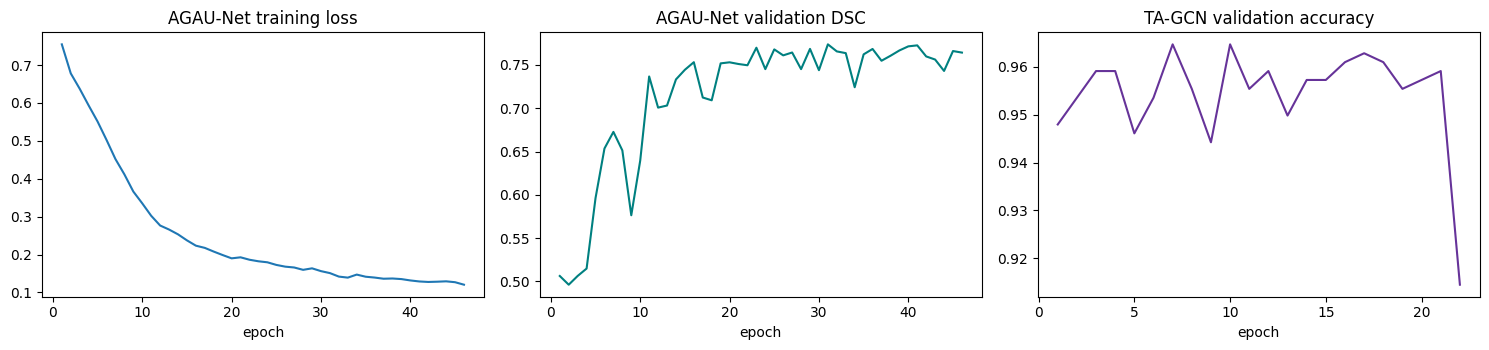

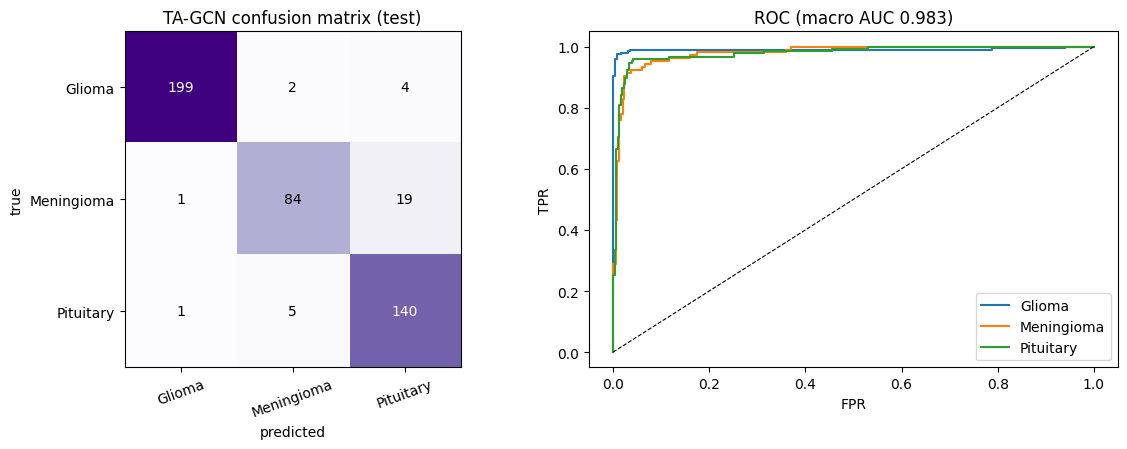

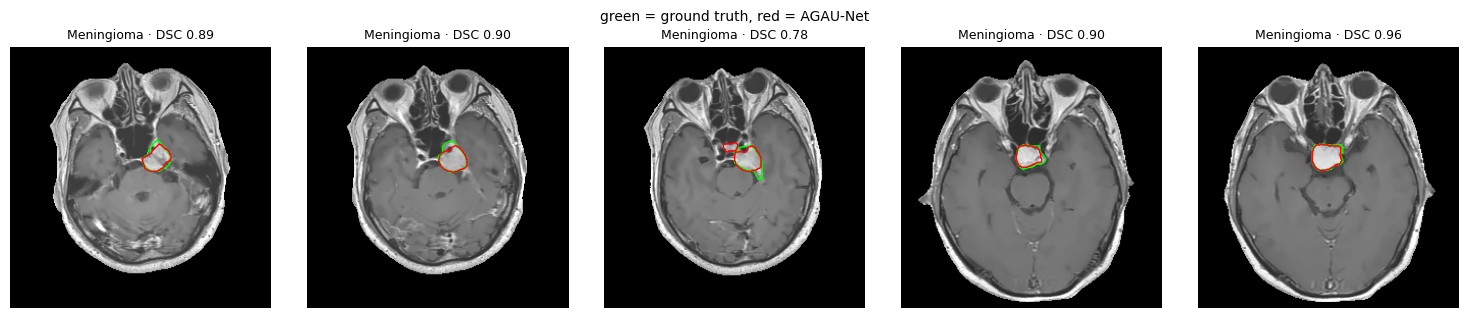

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
h = MAIN['seg_hist']; ax[0].plot(h.epoch, h.loss); ax[0].set_title('AGAU-Net training loss'); ax[0].set_xlabel('epoch')
ax[1].plot(h.epoch, h.val_dsc, c='teal'); ax[1].set_title('AGAU-Net validation DSC'); ax[1].set_xlabel('epoch')
h = MAIN['cls_hist']; ax[2].plot(h.epoch, h.val_acc, c='rebeccapurple'); ax[2].set_title('TA-GCN validation accuracy'); ax[2].set_xlabel('epoch')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/training_curves.png', dpi=150); plt.show()

y_te = MAIN['feats']['te']['y']; pred = MAIN['prob_te'].argmax(1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
cm = confusion_matrix(y_te, pred, labels=range(N_CLASSES))
ax[0].imshow(cm, cmap='Purples')
for i in range(N_CLASSES):
    for j in range(N_CLASSES): ax[0].text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
ax[0].set_xticks(range(N_CLASSES), CLASS_NAMES, rotation=20); ax[0].set_yticks(range(N_CLASSES), CLASS_NAMES)
ax[0].set_xlabel('predicted'); ax[0].set_ylabel('true'); ax[0].set_title('TA-GCN confusion matrix (test)')
for c in range(N_CLASSES):
    if (y_te == c).any() and (y_te != c).any():
        fpr, tpr, _ = roc_curve(y_te == c, MAIN['prob_te'][:, c]); ax[1].plot(fpr, tpr, label=CLASS_NAMES[c])
ax[1].plot([0, 1], [0, 1], 'k--', lw=0.8); ax[1].legend(); ax[1].set_title(f"ROC (macro AUC {MAIN['cls']['AUC']:.3f})")
ax[1].set_xlabel('FPR'); ax[1].set_ylabel('TPR')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/confusion_roc.png', dpi=150); plt.show()

# segmentation examples
te_t = tumor_only(te_idx)[:5]; pr = predict_probs(MAIN['seg_model'], te_t) > CFG['MASK_THR']
fig, ax = plt.subplots(1, len(te_t), figsize=(3 * len(te_t), 3.2))
for k, i in enumerate(te_t):
    a = ax[k] if len(te_t) > 1 else ax
    a.imshow(data['img'][i, 0].astype(np.float32), cmap='gray')
    a.contour(data['mask'][i], [0.5], colors='lime', linewidths=1); a.contour(pr[k], [0.5], colors='red', linewidths=1)
    a.set_title(f"{CLASS_NAMES[data['label'][i]]} · DSC {seg_scores(pr[k], data['mask'][i])['DSC']:.2f}", fontsize=9); a.axis('off')
plt.suptitle('green = ground truth, red = AGAU-Net', fontsize=10); plt.tight_layout()
plt.savefig(f'{FIG_DIR}/segmentation_examples.png', dpi=150); plt.show()

## 10 · Comparisons — baselines, ablation, grid search, cross-validation

[U-Net] ep   1 loss 0.7743 val DSC 0.4333 best 0.4333 (35s)
[U-Net] ep   2 loss 0.6985 val DSC 0.5173 best 0.5173 (33s)
[U-Net] ep   3 loss 0.6592 val DSC 0.4086 best 0.5173 (33s)
[U-Net] ep   4 loss 0.6218 val DSC 0.5703 best 0.5703 (34s)
[U-Net] ep   5 loss 0.5820 val DSC 0.5116 best 0.5703 (33s)
[U-Net] ep   6 loss 0.5416 val DSC 0.6288 best 0.6288 (33s)
[U-Net] ep   7 loss 0.4944 val DSC 0.5204 best 0.6288 (33s)
[U-Net] ep   8 loss 0.4513 val DSC 0.4440 best 0.6288 (33s)
[U-Net] ep   9 loss 0.3971 val DSC 0.6898 best 0.6898 (33s)
[U-Net] ep  10 loss 0.3597 val DSC 0.6868 best 0.6898 (33s)
[U-Net] ep  11 loss 0.3255 val DSC 0.7059 best 0.7059 (33s)
[U-Net] ep  12 loss 0.2950 val DSC 0.7124 best 0.7124 (33s)
[U-Net] ep  13 loss 0.2854 val DSC 0.6384 best 0.7124 (33s)
[U-Net] ep  14 loss 0.2545 val DSC 0.7243 best 0.7243 (33s)
[U-Net] ep  15 loss 0.2447 val DSC 0.6993 best 0.7243 (33s)
[U-Net] ep  16 loss 0.2323 val DSC 0.7129 best 0.7243 (33s)
[U-Net] ep  17 loss 0.2258 val DSC 0.742

,DSC,PA,IoU,HD95
Model,,,,
U-Net,0.759,0.993,0.671,13.179
Attention U-Net,0.773,0.993,0.680,16.759
V-Net,0.771,0.993,0.676,12.887
AGAU-Net (proposed),0.751,0.993,0.661,15.668


,Accuracy,Precision,Recall,Specificity,F1,AUC
Model,,,,,,
CNN-only,92.75,92.56,90.83,96.48,91.31,0.98
GCN-only,91.65,91.24,89.76,95.86,90.24,0.98
Transformer-only,92.31,91.55,90.66,96.34,90.85,0.98
TA-GCN (proposed),92.97,92.40,91.24,96.59,91.60,0.98


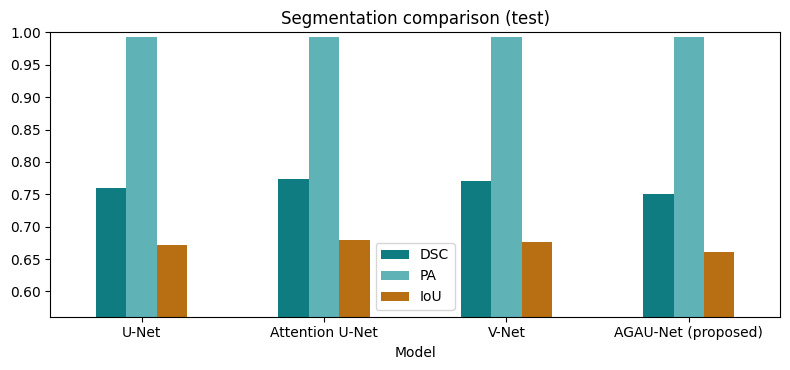

In [ ]:
SEG_TABLE, CLS_TABLE = None, None
if CFG['RUN_BASELINES']:
    rows = []
    for arch in ['unet', 'attunet', 'vnet']:
        m, _ = train_segmentation(arch, tr_idx, va_idx, 'main')
        r = evaluate_segmentation(m, te_idx)[['DSC', 'PA', 'IoU', 'HD95']].mean().to_dict(); r['Model'] = SEG_NAMES[arch]
        rows.append(r); del m; torch.cuda.empty_cache()
    rows.append({**MAIN['seg'], 'Model': SEG_NAMES['agau']})
    SEG_TABLE = pd.DataFrame(rows).set_index('Model').round(3)

    rows = []
    Xtr, Xva = (MAIN['hfsn'].transform(MAIN['feats'][s]['X']) for s in ('tr', 'va'))
    for kind in ['cnn', 'gcn', 'transformer']:
        m, _ = train_classifier(kind, Xtr, MAIN['feats']['tr']['y'], Xva, MAIN['feats']['va']['y'], MAIN['base_adj'], verbose=False)
        r = cls_metrics(MAIN['feats']['te']['y'], predict_cls(m, MAIN['Xte'])); r['Model'] = CLS_NAMES[kind]; rows.append(r)
    rows.append({**MAIN['cls'], 'Model': CLS_NAMES['tagcn']})
    CLS_TABLE = pd.DataFrame(rows).set_index('Model').round(2)
    display(SEG_TABLE); display(CLS_TABLE)

    fig, ax = plt.subplots(figsize=(8, 3.8))
    SEG_TABLE[['DSC', 'PA', 'IoU']].plot.bar(ax=ax, color=['#0F7C82', '#5FB3B7', '#B86E12'], rot=0)
    ax.set_ylim(max(0, SEG_TABLE[['DSC', 'PA', 'IoU']].values.min() - 0.1), 1); ax.set_title('Segmentation comparison (test)')
    plt.tight_layout(); plt.savefig(f'{FIG_DIR}/segmentation_comparison.png', dpi=150); plt.show()

In [ ]:
ABLATION = None
if CFG['RUN_ABLATION']:
    rows = [dict(Configuration='Full ICSS (proposed)', DSC=MAIN['seg']['DSC'], Accuracy=MAIN['cls']['Accuracy'])]
    r = run_pipeline(tr_idx, va_idx, te_idx, seg_arch='unet', tag='abl_noag')          # retrains Stage I without gates
    rows.append(dict(Configuration='w/o adaptive attention gates', DSC=r['seg']['DSC'], Accuracy=r['cls']['Accuracy'])); del r
    D_all = MAIN['feats']['tr']['X'].shape[-1]
    r = run_pipeline(tr_idx, va_idx, te_idx, topk=D_all, seg_model=MAIN['seg_model'], feats=MAIN['feats'], tag='abl_nohfsn')
    rows.append(dict(Configuration=f'w/o HFSN (all {D_all} features)', DSC=r['seg']['DSC'], Accuracy=r['cls']['Accuracy']))
    r = run_pipeline(tr_idx, va_idx, te_idx, cls_kind='gcn', seg_model=MAIN['seg_model'], feats=MAIN['feats'], tag='abl_notf')
    rows.append(dict(Configuration='w/o transformer block (GCN only)', DSC=r['seg']['DSC'], Accuracy=r['cls']['Accuracy']))
    ABLATION = pd.DataFrame(rows).set_index('Configuration').round(3); display(ABLATION)

In [ ]:
GRID = None
if CFG['RUN_GRID_SEARCH']:
    rows = []; f = MAIN['feats']; ytr, yva = f['tr']['y'], f['va']['y']
    for alpha in [0.4, 0.5, 0.6, 0.7, 0.8]:
        for k in [128, 256, 384, 512]:
            hf = HFSN(k, alpha, CFG['ENTROPY_BINS']).fit(f['tr']['X'], ytr)
            Xtr, Xva = hf.transform(f['tr']['X']), hf.transform(f['va']['X'])
            for tau in [0.6, 0.7, 0.8, 0.9]:
                m, _ = train_classifier('tagcn', Xtr, ytr, Xva, yva, MAIN['base_adj'], tau=tau, epochs=min(60, CFG['EPOCHS_CLS']), verbose=False)
                rows.append(dict(alpha=alpha, k=k, tau=tau, val_acc=accuracy_score(yva, predict_cls(m, Xva).argmax(1))))
                print(rows[-1])
    GRID = pd.DataFrame(rows).sort_values('val_acc', ascending=False); display(GRID.head(10))
    print('best on validation:', GRID.iloc[0].to_dict(), '-> set CFG ALPHA/TOPK/TAU and re-run §9 to use it')

In [ ]:
CV = None
if CFG['RUN_CV']:
    # patient-level k-fold of the WHOLE pipeline; inside each fold, 15 % of the training patients are used for validation
    gkf = GroupKFold(n_splits=CFG['N_FOLDS']); recs = []
    all_idx = np.arange(len(data['label']))
    for fold, (trv, te) in enumerate(gkf.split(all_idx, data['label'], data['pid'])):
        sub_tr, sub_va, _ = patient_split(data['pid'][trv], data['label'][trv], fr=(0.85, 0.15, 0.0), seed=CFG['SEED'] + fold)
        tr, va = trv[sub_tr], trv[sub_va]
        r = run_pipeline(tr, va, te, tag=f'cv{fold}')
        rec = dict(fold=fold, **{'seg_' + k: float(v) for k, v in r['seg'].items()}, **{'cls_' + k: v for k, v in r['cls'].items()})
        if CFG['RUN_BASELINES']:
            Xtr, Xva = (r['hfsn'].transform(r['feats'][s]['X']) for s in ('tr', 'va'))
            for arch in ['unet', 'attunet', 'vnet']:
                m, _ = train_segmentation(arch, tr, va, f'cv{fold}')
                rec[f'seg_DSC_{arch}'] = float(evaluate_segmentation(m, te).DSC.mean()); del m
            for kind in ['cnn', 'gcn', 'transformer']:
                m, _ = train_classifier(kind, Xtr, r['feats']['tr']['y'], Xva, r['feats']['va']['y'], r['base_adj'], verbose=False)
                rec[f'cls_Acc_{kind}'] = accuracy_score(r['feats']['te']['y'], predict_cls(m, r['Xte']).argmax(1)) * 100
        recs.append(rec); del r; torch.cuda.empty_cache()
        print(f'fold {fold}:', {k: round(v, 3) for k, v in rec.items()})
    CV = pd.DataFrame(recs)
    display(CV.describe().loc[['mean', 'std']].round(3))
    if CFG['RUN_BASELINES']:
        # one-sided paired Wilcoxon signed-rank (proposed > baseline). NB: with n = 5 folds the smallest attainable
        # p-value is 1/32 = 0.031 one-sided and 0.0625 two-sided, so a two-sided test can never reach p < 0.05.
        def safe_wilcoxon(a, b):
            try: return float(wilcoxon(a, b, alternative='greater').pvalue)
            except ValueError: return float('nan')   # e.g. all paired differences are zero
        tests = []
        for arch in ['unet', 'attunet', 'vnet']:
            tests.append(dict(comparison=f'AGAU-Net vs {SEG_NAMES[arch]} (DSC)',
                              p=safe_wilcoxon(CV.seg_DSC, CV[f'seg_DSC_{arch}'])))
        for kind in ['cnn', 'gcn', 'transformer']:
            tests.append(dict(comparison=f'TA-GCN vs {CLS_NAMES[kind]} (accuracy)',
                              p=safe_wilcoxon(CV.cls_Accuracy, CV[f'cls_Acc_{kind}'])))
        display(pd.DataFrame(tests))

## 11 · Explainable AI — Grad-CAM (Stage I) · SHAP (Stage II features) · LIME (Stage III nodes) · unified report

In [ ]:
class SegGradCAM:
    # Grad-CAM on the final AGAU-Net decoder block; target = sum of logits inside the predicted mask
    def __init__(s, model):
        s.model = model; s.acts = s.grads = None
        model.gradcam_layer().register_forward_hook(s._fwd)
    def _fwd(s, m, i, o):
        s.acts = o
        if o.requires_grad: o.register_hook(lambda g: setattr(s, 'grads', g))
    def __call__(s, x):
        s.model.eval(); x = x.clone().requires_grad_(True)
        logits = s.model(x); m = (torch.sigmoid(logits) > CFG['MASK_THR']).float()
        target = (logits * m).sum() if m.sum() > 0 else logits.sum()
        s.model.zero_grad(); target.backward()
        w = s.grads.mean((2, 3), keepdim=True)
        cam = F.relu((w * s.acts).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode='bilinear', align_corners=False)[0, 0].detach().cpu().numpy()
        return cam / (cam.max() + 1e-8), torch.sigmoid(logits)[0, 0].detach().cpu().numpy()

gradcam = SegGradCAM(MAIN['seg_model'])
def cam_for(i):
    return gradcam(torch.from_numpy(data['img'][i:i + 1].astype(np.float32)).to(DEVICE))

# quantitative check: share of Grad-CAM energy that falls inside the ground-truth tumor
te_t = tumor_only(te_idx)
energy = [float((c := cam_for(i)[0])[data['mask'][i] > 0].sum() / (c.sum() + 1e-8)) for i in te_t[:200]]
tumor_frac = [data['mask'][i].mean() for i in te_t[:200]]
print(f'Grad-CAM energy inside GT tumor: {np.mean(energy) * 100:.1f}% (tumor covers {np.mean(tumor_frac) * 100:.1f}% of the image)')

Grad-CAM energy inside GT tumor: 88.6% (tumor covers 1.8% of the image)


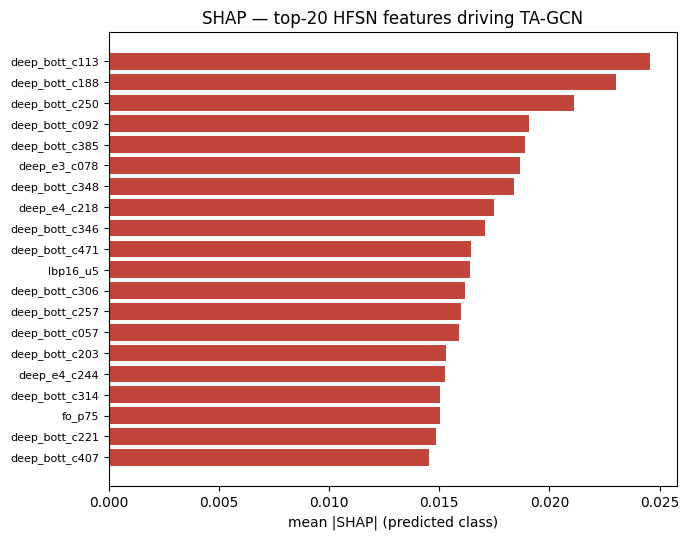

SHAP importance by feature family:
 deep_bott    0.458
deep_e3      0.194
deep_e4      0.172
glcm         0.090
fo           0.031
lbp16        0.029
lbp8         0.021
hist         0.005
dtype: float64


In [ ]:
import shap
class ProbWrapper(nn.Module):
    def __init__(s, m): super().__init__(); s.m = m
    def forward(s, x): return torch.softmax(s.m(x), -1)

def shap_values(model, X_bg, X_ex):
    w = ProbWrapper(model).to(DEVICE).eval()
    bg = torch.as_tensor(X_bg, device=DEVICE); ex = torch.as_tensor(X_ex, device=DEVICE)
    try:
        sv = shap.GradientExplainer(w, bg).shap_values(ex)
        sv = np.stack(sv, -1) if isinstance(sv, list) else np.asarray(sv)
    except Exception as e:                       # fallback: expected gradients (the estimator behind GradientExplainer)
        print('shap.GradientExplainer failed (%s); using expected-gradients fallback' % e)
        rng = np.random.default_rng(0); out = []
        for c in range(N_CLASSES):
            acc = torch.zeros_like(ex)
            for _ in range(50):
                ref = bg[rng.integers(0, len(bg), len(ex))]; a = torch.rand(len(ex), 1, 1, device=DEVICE)
                z = (ref + a * (ex - ref)).requires_grad_(True)
                g, = torch.autograd.grad(w(z)[:, c].sum(), z); acc += g * (ex - ref)
            out.append((acc / 50).cpu().numpy())
        sv = np.stack(out, -1)
    return sv                                    # [n, nodes, features, classes]

rng = np.random.default_rng(CFG['SEED'])
Xtr_sel = MAIN['hfsn'].transform(MAIN['feats']['tr']['X'])
bg = Xtr_sel[rng.choice(len(Xtr_sel), min(CFG['SHAP_BACKGROUND'], len(Xtr_sel)), replace=False)]
ex_ids = rng.choice(len(MAIN['Xte']), min(CFG['SHAP_SAMPLES'], len(MAIN['Xte'])), replace=False)
SV = shap_values(MAIN['clf'], bg, MAIN['Xte'][ex_ids])
pred_ex = MAIN['prob_te'][ex_ids].argmax(1)
sv_pred = SV[np.arange(len(ex_ids)), :, :, pred_ex]                      # attributions for the predicted class
imp = np.abs(sv_pred).sum(1).mean(0)                                     # sum over nodes, mean over cases
sel_names = FEATURE_NAMES[MAIN['hfsn'].idx]
order = np.argsort(-imp)[:20]
SHAP_TABLE = pd.DataFrame({'feature': sel_names[order], 'mean|SHAP|': imp[order]})
plt.figure(figsize=(7, 5.5)); plt.barh(range(20)[::-1], imp[order], color='#C2453B')
plt.yticks(range(20)[::-1], sel_names[order], fontsize=8); plt.xlabel('mean |SHAP| (predicted class)')
plt.title('SHAP — top-20 HFSN features driving TA-GCN'); plt.tight_layout(); plt.savefig(f'{FIG_DIR}/shap_top20.png', dpi=150); plt.show()
grp = pd.Series(imp, index=[n.split('_')[0] if not n.startswith('deep') else 'deep_' + n.split('_')[1] for n in sel_names]).groupby(level=0).sum()
print('SHAP importance by feature family:\n', (grp / grp.sum()).sort_values(ascending=False).round(3))

In [ ]:
from lime import lime_base
from sklearn.metrics import pairwise_distances

def lime_nodes(model, x, label, n_samples=None, kernel_width=0.25, seed=0):
    # LIME at graph-node level: interpretable components = nodes on/off; surrogate = weighted ridge regression
    n_samples = n_samples or CFG['LIME_SAMPLES']
    rng = np.random.default_rng(seed); N = x.shape[0]
    Z = rng.integers(0, 2, (n_samples, N)).astype(np.float32); Z[0] = 1
    Z[Z.sum(1) == 0, rng.integers(0, N)] = 1
    P = predict_cls(model, np.repeat(x[None], n_samples, 0), node_mask=Z.astype(bool))
    d = pairwise_distances(Z, Z[:1], metric='cosine').ravel()
    lb = lime_base.LimeBase(kernel_fn=lambda d: np.sqrt(np.exp(-(d ** 2) / kernel_width ** 2)), random_state=seed)
    _, exp, score, _ = lb.explain_instance_with_data(Z, P, d, label, num_features=N)
    w = np.zeros(N);
    for j, v in exp: w[j] = v
    return w, score

def node_map(weights, boxes, S):
    G = CFG['GRID']; M = np.zeros((N_CH, S, S), np.float32)
    for m in range(N_CH):
        for k, (x0, y0, x1, y1) in enumerate(boxes):
            M[m, int(y0):int(np.ceil(y1)), int(x0):int(np.ceil(x1))] = weights[m * G * G + k]
    return M

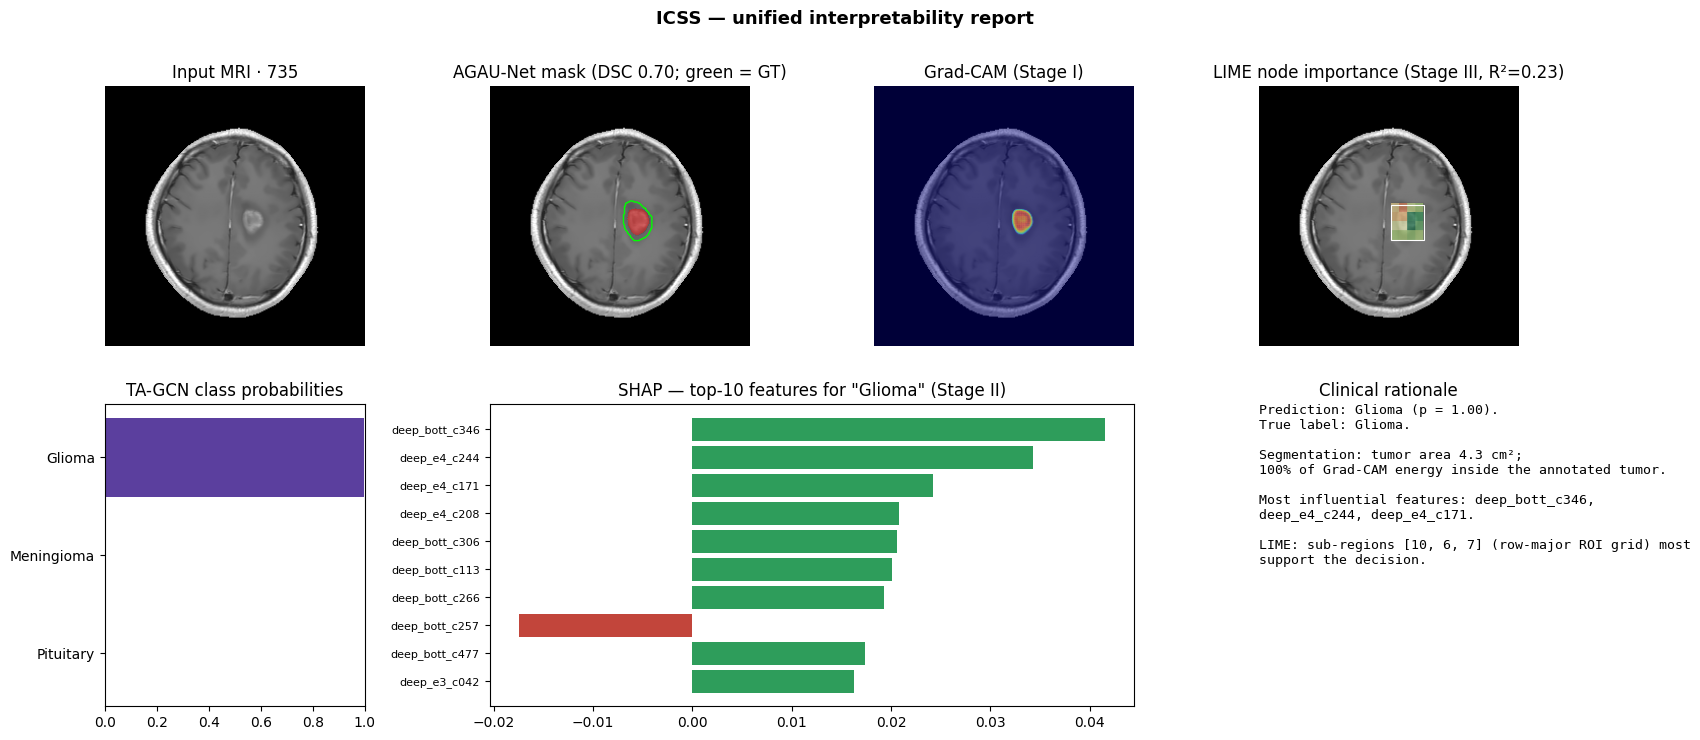

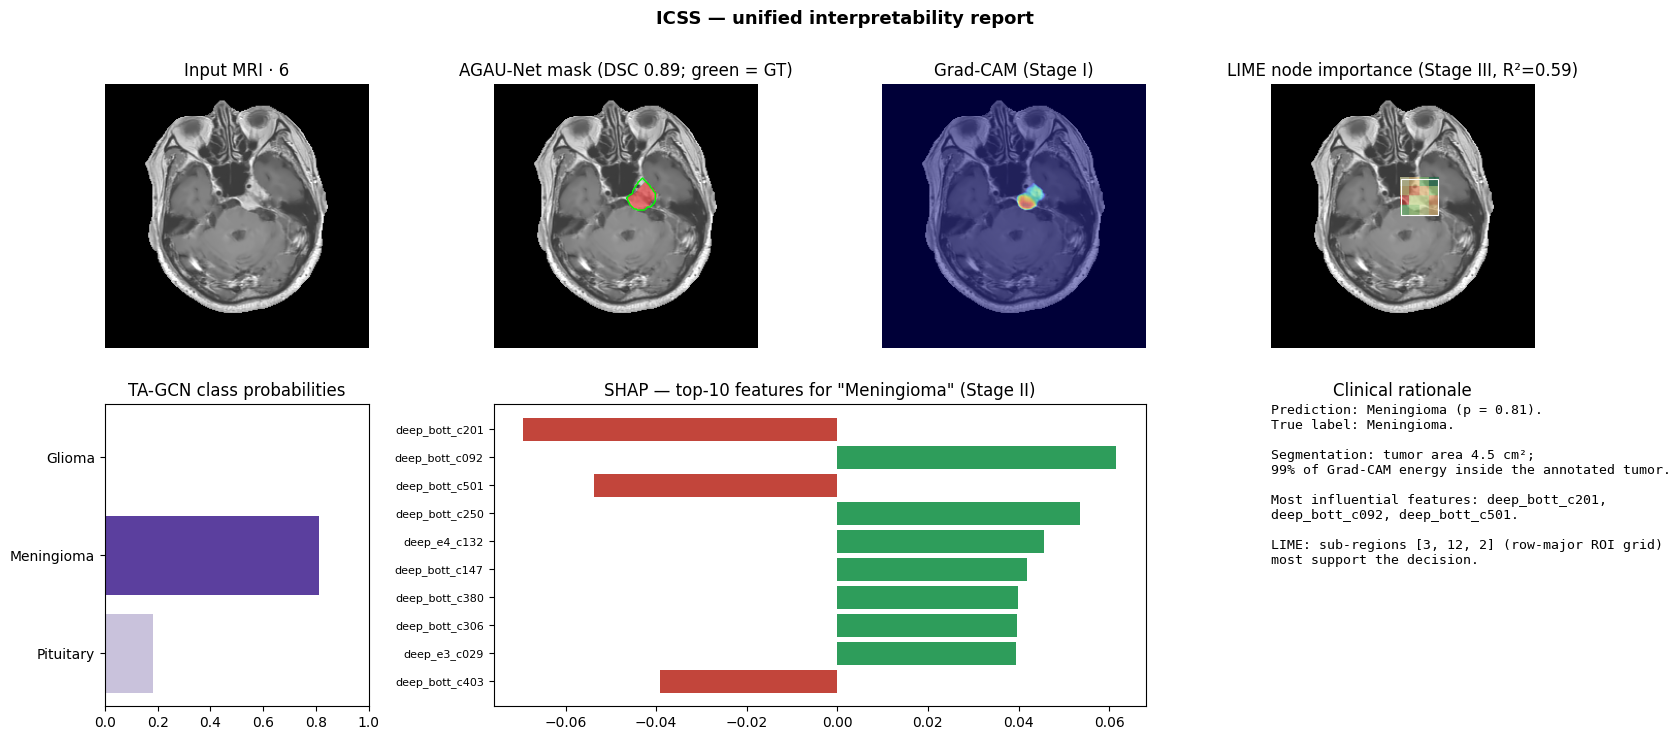

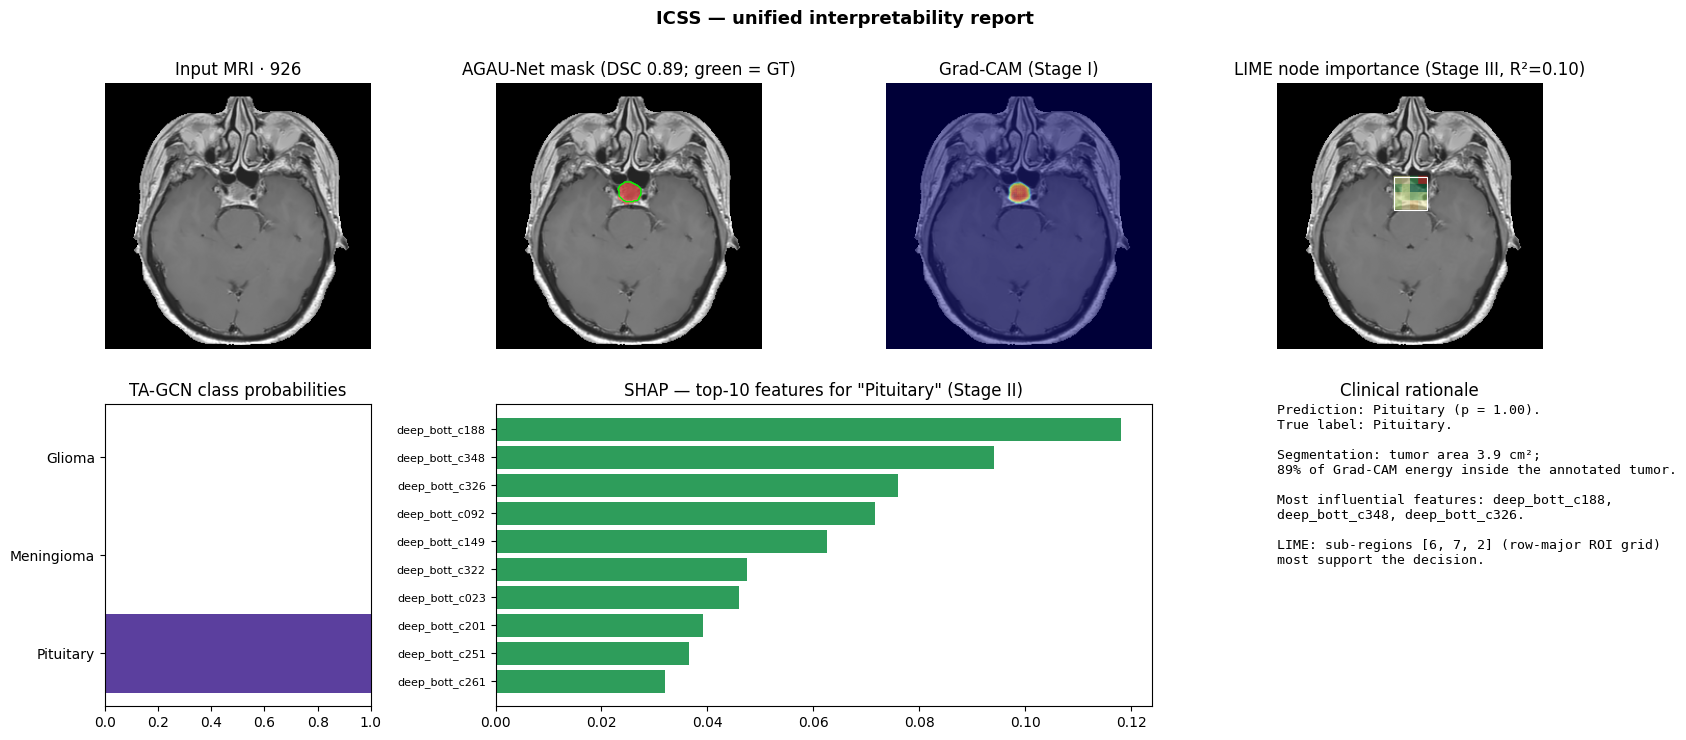

In [ ]:
def clinician_report(j, save=True, show=True):
    # j = position inside the test set
    f = MAIN['feats']['te']; i = int(f['idx'][j]); S = CFG['IMG_SIZE']
    prob = MAIN['prob_te'][j]; c = int(prob.argmax()); x = MAIN['Xte'][j]
    cam, segp = cam_for(i)
    pm = f['pred_mask'][j].astype(bool); gt = data['mask'][i].astype(bool)
    sv = shap_values(MAIN['clf'], bg, x[None])[0, :, :, c]                  # [nodes, features]
    fimp = sv.sum(0); top = np.argsort(-np.abs(fimp))[:10]
    lw, lscore = lime_nodes(MAIN['clf'], x, c)
    L = node_map(lw, f['boxes'][j], S)
    img = data['img'][i, 0].astype(np.float32)

    fig = plt.figure(figsize=(17, 7.5)); gs = fig.add_gridspec(2, 4)
    a = fig.add_subplot(gs[0, 0]); a.imshow(img, cmap='gray'); a.set_title(f'Input {MODALITIES[0]} · {data["id"][i]}'); a.axis('off')
    a = fig.add_subplot(gs[0, 1]); a.imshow(img, cmap='gray'); a.imshow(np.ma.masked_where(~pm, pm), cmap='autumn', alpha=0.45)
    if gt.any(): a.contour(gt, [0.5], colors='lime', linewidths=1)
    d = seg_scores(pm, gt)['DSC'] if gt.any() else float('nan')
    a.set_title(f'AGAU-Net mask (DSC {d:.2f}; green = GT)'); a.axis('off')
    a = fig.add_subplot(gs[0, 2]); a.imshow(img, cmap='gray'); a.imshow(cam, cmap='jet', alpha=0.45); a.set_title('Grad-CAM (Stage I)'); a.axis('off')
    a = fig.add_subplot(gs[0, 3]); vmax = np.abs(L).max() + 1e-8
    a.imshow(img, cmap='gray'); a.imshow(np.ma.masked_where(L[0] == 0, L[0]), cmap='RdYlGn', vmin=-vmax, vmax=vmax, alpha=0.55)
    x0, y0, x1, y1 = roi_box(pm, data['brain'][i].astype(bool)); a.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec='white', lw=0.8))
    a.set_title(f'LIME node importance (Stage III, R²={lscore:.2f})'); a.axis('off')
    a = fig.add_subplot(gs[1, 0]); a.barh(range(N_CLASSES)[::-1], prob, color=['#5B3F9E' if k == c else '#C9C2DC' for k in range(N_CLASSES)])
    a.set_yticks(range(N_CLASSES)[::-1], CLASS_NAMES); a.set_xlim(0, 1); a.set_title('TA-GCN class probabilities')
    a = fig.add_subplot(gs[1, 1:3]); a.barh(range(10)[::-1], fimp[top], color=['#2E9D5B' if v > 0 else '#C2453B' for v in fimp[top]])
    a.set_yticks(range(10)[::-1], sel_names[top], fontsize=8); a.set_title(f'SHAP — top-10 features for "{CLASS_NAMES[c]}" (Stage II)')
    a = fig.add_subplot(gs[1, 3]); a.axis('off')
    inside = float(cam[gt].sum() / (cam.sum() + 1e-8)) if gt.any() else float('nan')
    pos_nodes = [int(k) for k in np.argsort(-lw)[:3] if lw[k] > 0]
    rationale = (f"Prediction: {CLASS_NAMES[c]} (p = {prob[c]:.2f}).\n"
                 f"True label: {CLASS_NAMES[data['label'][i]]}.\n\n"
                 f"Segmentation: tumor area {pm.sum() * CFG['PIXEL_MM'] ** 2 / 100:.1f} cm²;\n"
                 f"{inside * 100:.0f}% of Grad-CAM energy inside the annotated tumor.\n\n"
                 f"Most influential features: {', '.join(sel_names[top[:3]])}.\n\n"
                 f"LIME: sub-regions {pos_nodes} (row-major ROI grid) most support the decision.")
    a.text(0, 1, rationale, va='top', fontsize=9.5, family='monospace', wrap=True); a.set_title('Clinical rationale')
    plt.suptitle('ICSS — unified interpretability report', fontsize=13, weight='bold'); plt.tight_layout()
    if save: plt.savefig(f'{FIG_DIR}/report_{data["id"][i]}.png', dpi=150)
    if show: plt.show()
    else: plt.close()
    rep = dict(id=str(data['id'][i]), prediction=CLASS_NAMES[c], probabilities=dict(zip(CLASS_NAMES, map(float, prob))),
               true_label=CLASS_NAMES[data['label'][i]], dsc=float(d), gradcam_energy_in_tumor=inside,
               top_features=[(str(sel_names[k]), float(fimp[k])) for k in top], lime_node_weights=lw.round(4).tolist())
    if save: json.dump(rep, open(f'{CFG["WORK_DIR"]}/report_{data["id"][i]}.json', 'w'), indent=1)
    return rep

# one report per class from the test set
for c in range(N_CLASSES):
    js = np.where(MAIN['feats']['te']['y'] == c)[0]
    if len(js): clinician_report(int(js[0]))

In [ ]:
# interactive clinician dashboard (Colab): choose any test case
try:
    import ipywidgets as W
    from IPython.display import clear_output
    opts = [(f"{data['id'][int(i)]} · {CLASS_NAMES[data['label'][int(i)]]}", j) for j, i in enumerate(MAIN['feats']['te']['idx'])]
    dd = W.Dropdown(options=opts, description='Test case:', layout=W.Layout(width='420px')); out = W.Output()
    def _show(ch):
        with out:
            clear_output(wait=True); clinician_report(ch['new'], save=False)
    dd.observe(_show, names='value'); display(W.VBox([dd, out]))
except Exception as e:
    print('ipywidgets unavailable:', e)

## 12 · Computational efficiency & export

In [ ]:
def timeit(fn, n=20):
    for _ in range(3): fn()
    if DEVICE.type == 'cuda': torch.cuda.synchronize()
    t = time.time()
    for _ in range(n): fn()
    if DEVICE.type == 'cuda': torch.cuda.synchronize()
    return (time.time() - t) / n * 1000

x1 = torch.from_numpy(data['img'][te_idx[:1]].astype(np.float32)).to(DEVICE)
MAIN['seg_model'].eval(); MAIN['clf'].eval()
with torch.no_grad():
    t_seg = timeit(lambda: MAIN['seg_model'](x1))
    xg = torch.as_tensor(MAIN['Xte'][:1], device=DEVICE); t_cls = timeit(lambda: MAIN['clf'](xg))
t0 = time.time(); _ = extract_features(MAIN['seg_model'], te_idx[:10]); t_feat = (time.time() - t0) / 10 * 1000
EFF = pd.DataFrame([dict(stage='AGAU-Net segmentation / slice', ms=t_seg), dict(stage='Feature bank + HFSN / case', ms=t_feat),
                    dict(stage='TA-GCN classification / case', ms=t_cls), dict(stage='End-to-end (excl. XAI)', ms=t_seg + t_feat + t_cls)]).round(1)
display(EFF)

,stage,ms
0,AGAU-Net segmentation / slice,21.0
1,Feature bank + HFSN / case,175.6
2,TA-GCN classification / case,1.5
3,End-to-end (excl. XAI),198.1


In [ ]:
torch.save(MAIN['seg_model'].state_dict(), f"{CFG['WORK_DIR']}/agau_net.pt")
torch.save(MAIN['clf'].state_dict(), f"{CFG['WORK_DIR']}/ta_gcn.pt")
np.savez(f"{CFG['WORK_DIR']}/hfsn.npz", idx=MAIN['hfsn'].idx, mu=MAIN['hfsn'].mu, sd=MAIN['hfsn'].sd,
         score=MAIN['hfsn'].score, mig=MAIN['hfsn'].mig, H=MAIN['hfsn'].H, names=FEATURE_NAMES)
results = dict(config=CFG, classes=CLASS_NAMES, n_slices=int(len(data['label'])),
               split=dict(train=len(tr_idx), val=len(va_idx), test=len(te_idx)),
               segmentation=MAIN['seg'], classification=MAIN['cls'],
               seg_table=None if SEG_TABLE is None else SEG_TABLE.reset_index().to_dict('records'),
               cls_table=None if CLS_TABLE is None else CLS_TABLE.reset_index().to_dict('records'),
               ablation=None if ABLATION is None else ABLATION.reset_index().to_dict('records'),
               cv=None if CV is None else CV.to_dict('records'), shap_top20=SHAP_TABLE.to_dict('records'),
               efficiency_ms=EFF.to_dict('records'))
json.dump(results, open(f"{CFG['WORK_DIR']}/results.json", 'w'), indent=1, default=float)
MAIN['seg_df'].to_csv(f"{CFG['WORK_DIR']}/segmentation_per_slice.csv", index=False)
shutil.make_archive('/content/icss_results' if os.path.isdir('/content') else os.path.join(CFG['WORK_DIR'], '..', 'icss_results'),
                    'zip', CFG['WORK_DIR'], '.')
print('saved models, HFSN, figures, reports and results.json to', CFG['WORK_DIR'])
try:
    from google.colab import files; files.download('/content/icss_results.zip')
except Exception:
    pass